# Capas horarias de Dept1: comparación con número fijo de clusters
Se mantiene íntegro el algoritmo base: entropía espectral, suma de pesos al agregar grafos, cinco proyecciones Erdős–Rényi con p=0.5, fusiones dentro del mismo bucket y posterior búsqueda global. No se incorporan Hamming, búsqueda híbrida ni Taylor.

Cada capa representa una hora relativa del registro, sin mezclar días. Se conservan los 309 usuarios del archivo; las horas sin interacciones no forman capas. Se seleccionan hasta 1000 horas activas. Los timestamps no identifican fechas de calendario ni horas locales.

El análisis principal compara diez semillas emparejadas para B=10 y B=40 con un baseline exhaustivo determinista, a los mismos números de clusters. q(C) se conserva como medida descriptiva, sin seleccionar el corte mediante el codo. Se guardan jerarquías completas para reutilizarlas con otros cortes. No se calculan ARI ni NMI en el análisis.


In [10]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
import os
import copy
from pathlib import Path
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# ----------------------------------------------------
# 1. Definición del Kernel de Frobenius para LSH
# ----------------------------------------------------

def projection_frobenius(A, B):
    return float(np.sum(A * B))

def hash_p_stable(projection, r, offset):
    if r <= 0:
        return 0
    return int(np.floor((projection + offset) / r))

def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g

def get_active_nodes(g):
    if 'active_nodes' in g.graph:
        return g.graph['active_nodes']
    nodes = sorted(list(set([n for n, d in g.degree() if d > 0])))
    g.graph['active_nodes'] = nodes
    return nodes

def get_adjacency(g, N):
    # Dense working array only; never retain one per input layer.
    A = nx.to_numpy_array(g, nodelist=range(N), weight='weight', dtype=float)
    np.fill_diagonal(A, 0)
    return A

def get_density_matrix(A):
    num_edges = np.sum(A) / 2.0
    if num_edges == 0:
        return np.zeros_like(A)
    degrees = np.sum(A, axis=1)
    L = np.diag(degrees) - A
    return L / (2.0 * num_edges)

def entropy_from_rho(rho):
    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0
    eigvals = eigvals[eigvals > 1e-12]
    return float(-np.sum(eigvals * np.log2(eigvals)))

def von_newmann_entropy(g, N_pad=None):
    if 'vn_entropy' in g.graph:
        return g.graph['vn_entropy']

    act = get_active_nodes(g)
    if len(act) == 0:
        entropy = 0.0
    else:
        A = nx.adjacency_matrix(g, nodelist=act, weight='weight').toarray().astype(float)
        sum_A = np.sum(A)
        L = np.diag(np.sum(A, axis=1)) - A
        rho = L / sum_A
        entropy = entropy_from_rho(rho)
        
    g.graph['vn_entropy'] = entropy
    return entropy

def aggregate(g1, g2, N=None):
    g = nx.Graph()
    for u, v, d in g1.edges(data=True):
        g.add_edge(u, v, weight=d.get('weight', 1.0))
    for u, v, d in g2.edges(data=True):
        if g.has_edge(u, v):
            g[u][v]['weight'] += d.get('weight', 1.0)
        else:
            g.add_edge(u, v, weight=d.get('weight', 1.0))
            
    if N is not None:
        g.add_nodes_from(range(N))
    return g

def js_divergence(g1, g2, N_pad=None):
    act1 = get_active_nodes(g1)
    act2 = get_active_nodes(g2)
    union_nodes = sorted(list(set(act1) | set(act2)))
    
    if len(union_nodes) == 0:
        return 0.0
        
    A1 = nx.adjacency_matrix(g1, nodelist=union_nodes, weight='weight').toarray().astype(float)
    A2 = nx.adjacency_matrix(g2, nodelist=union_nodes, weight='weight').toarray().astype(float)
    
    sum_A1 = np.sum(A1)
    sum_A2 = np.sum(A2)
    
    rho1 = (np.diag(np.sum(A1, axis=1)) - A1) / sum_A1 if sum_A1 > 0 else np.zeros_like(A1)
    rho2 = (np.diag(np.sum(A2, axis=1)) - A2) / sum_A2 if sum_A2 > 0 else np.zeros_like(A2)
    
    rho_mix = (rho1 + rho2) / 2.0
    
    h_mix = entropy_from_rho(rho_mix)
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2.0
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)

def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad, proj_func):
    bucket_id = ""
    A = get_density_matrix(get_adjacency(g, N_pad))

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)
        proj = proj_func(A, A_er)

        min_proj, max_proj, offset = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r, offset)
        bucket_id += f"{hash_bin}_"

    return bucket_id

def quality(active, clusters, h_total=None, N_pad=None):
    active = list(active)
    if not active:
        return 0.0
    if h_total is None:
        N_pad = N_pad or max(clusters[i].number_of_nodes() for i in active)
        total = np.zeros((N_pad, N_pad))
        for i in active:
            add_density(total, clusters[i])
        h_total = entropy_from_rho(total / len(active))
    return 0.0 if h_total <= 1e-12 else float(
        1 - sum(von_newmann_entropy(clusters[i]) for i in active) / len(active) / h_total)

def get_rho_sub(g):
    act = get_active_nodes(g)
    if len(act) == 0:
        return np.zeros((1, 1))
    A = nx.adjacency_matrix(g, nodelist=act, weight='weight').toarray().astype(float)
    sum_A = np.sum(A)
    return (np.diag(np.sum(A, axis=1)) - A) / sum_A if sum_A > 0 else np.zeros_like(A)


def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False

# ----------------------------------------------------
# 2. Controladores LSH-HLA y Baseline
# ----------------------------------------------------

def build_lsh_buckets(graphs, num_proj, B, proj_func, p_er=0.5):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in range(num_proj):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)
        A_er = get_adjacency(erg, N_pad)

        projections = []
        for g in graphs:
            A = get_density_matrix(get_adjacency(g, N_pad))
            proj = proj_func(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)
        r = (max_proj - min_proj) / B
        offset = np.random.uniform(0, r) if r > 0 else 0.0
        projection_ranges.append((min_proj, max_proj, offset))
        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r, offset)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)
    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges

def hierarchical_bucket_heap_dynamic(graphs, buckets, bucket_ids, random_graphs,
                                     projection_ranges, B, proj_func, epsilon=np.inf):
    return memory_bounded_hierarchy(
        graphs, epsilon=epsilon, bucket_ids=bucket_ids,
        rehash=lambda g: get_bucket_id_for_graph(
            g, random_graphs, B, projection_ranges,
            graphs[0].number_of_nodes(), proj_func))

def shclust_heap_dynamic(graphs, num_proj=3, B=10, proj_func=projection_frobenius, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B,
        proj_func=proj_func
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        proj_func=proj_func,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids

def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    """Exact global minimum, with one nearest candidate per active cluster."""
    Z, clusters, active, _ = memory_bounded_hierarchy(graphs, epsilon=epsilon)
    return Z, clusters, active

# Helper functions for evaluation
def get_cluster_memberships(Z, num_graphs, target_merges):
    memberships = {i: [i] for i in range(num_graphs)}
    active = set(range(num_graphs))
    
    for step in range(min(target_merges, len(Z))):
        row = Z[step]
        c_i = int(row[0])
        c_j = int(row[1])
        new_id = int(row[4])
        
        memberships[new_id] = memberships.pop(c_i) + memberships.pop(c_j)
        active.remove(c_i)
        active.remove(c_j)
        active.add(new_id)
        
    return {c: memberships[c] for c in active}

def get_cluster_labels(Z, num_graphs, k_star):
    cluster_members = get_cluster_memberships(Z, num_graphs, k_star)
    labels = np.zeros(num_graphs, dtype=int)
    for c_idx, (c_id, members) in enumerate(cluster_members.items()):
        for m in members:
            labels[m] = c_idx
    return labels
def elbow_method(q):
    """
    Método del codo basado en distancia perpendicular a la recta
    entre (1, q(1)) y (m, q(m)).
    """
    q = np.asarray(q, dtype=float)
    m = len(q)

    x1, y1 = 1, q[0]
    x2, y2 = m, q[-1]

    dx = x2 - x1
    dy = y2 - y1

    norm = np.sqrt(dx**2 + dy**2)

    distances = np.zeros(m)
    for i in range(m):
        x0 = i + 1
        y0 = q[i]
        area = abs(dy * (x0 - x1) - dx * (y0 - y1))
        distances[i] = area / norm

    k_star = int(np.argmax(distances) + 1)
    return k_star, distances


def fresh_graphs(graphs):
    """Reset numerical caches without duplicating immutable graph topology."""
    for g in graphs:
        for key in ('adjacency', 'active_nodes', 'vn_entropy'):
            g.graph.pop(key, None)
    return list(graphs)


def add_density(total, g, factor=1.0):
    """Accumulate a normalized Laplacian using edges, without a dense copy."""
    weight_sum = sum(d.get('weight', 1.0) for u, v, d in g.edges(data=True) if u != v)
    if weight_sum <= 0:
        return
    scale = factor / (2.0 * weight_sum)
    for u, v, d in g.edges(data=True):
        if u == v:
            continue
        w = d.get('weight', 1.0) * scale
        total[u, u] += w
        total[v, v] += w
        total[u, v] -= w
        total[v, u] -= w


def memory_bounded_hierarchy(graphs, epsilon=np.inf, bucket_ids=None, rehash=None):
    """O(L) candidate storage; exact search within the currently allowed pairs.

    Distances are recomputed when a cached nearest neighbor disappears. This
    trades runtime for bounded memory and does not approximate the baseline.
    Only active aggregate graphs are retained; Z reconstructs past memberships.
    """
    if not graphs:
        return [], {}, set(), defaultdict(set)
    n = len(graphs)
    N = graphs[0].number_of_nodes()
    clusters = dict(enumerate(graphs))
    active = set(clusters)
    bids = dict(enumerate(bucket_ids)) if bucket_ids is not None else {}
    global_mode = bucket_ids is None
    nearest = {}
    rho_sum = np.zeros((N, N), dtype=float)
    for g in tqdm(graphs, desc="Acumulando matrices de densidad"):
        add_density(rho_sum, g)
    Z = []

    def allowed(i, j):
        return i != j and (global_mode or bids[i] == bids[j])

    def candidate(i, j):
        # Stable tie-breaking independent of set traversal.
        a, b = sorted((i, j))
        return (js_divergence(clusters[a], clusters[b]), a, b)

    def refresh(i):
        best = None
        for j in sorted(active):
            if allowed(i, j):
                value = candidate(i, j)
                if best is None or value < best:
                    best = value
        nearest[i] = best

    for i in tqdm(sorted(active), desc="Buscando vecinos iniciales (memoria lineal)"):
        refresh(i)
    progress = tqdm(total=max(n - 1, 0), desc="Fusiones")
    try:
        while len(active) > 1:
            candidates = [v for v in nearest.values() if v is not None]
            if not candidates:
                if global_mode:
                    break
                global_mode = True
                for i in sorted(active):
                    refresh(i)
                continue
            dist, i, j = min(candidates)
            if dist > epsilon:
                break
            same_bucket = bucket_ids is not None and bids[i] == bids[j]
            merged = aggregate(clusters[i], clusters[j], N)
            add_density(rho_sum, clusters[i], -1.0)
            add_density(rho_sum, clusters[j], -1.0)
            add_density(rho_sum, merged)
            new_id = n + len(Z)
            for old in (i, j):
                active.remove(old)
                del clusters[old]
                del nearest[old]
            clusters[new_id] = merged
            active.add(new_id)
            if bucket_ids is not None:
                bids[new_id] = rehash(merged) if not global_mode else "global"
            h_total = entropy_from_rho(rho_sum / len(active))
            q = quality(active, clusters, h_total=h_total, N_pad=N)
            row = [i, j, dist, q, new_id]
            if bucket_ids is not None:
                row += [bids[new_id], same_bucket, global_mode]
            Z.append(row)
            for other in sorted(active - {new_id}):
                old_best = nearest[other]
                if old_best is not None and (i in old_best[1:] or j in old_best[1:]):
                    refresh(other)
                elif allowed(other, new_id):
                    value = candidate(other, new_id)
                    if old_best is None or value < old_best:
                        nearest[other] = value
            refresh(new_id)
            if bucket_ids is not None:
                del bids[i], bids[j]
            progress.update(1)
    finally:
        progress.close()
    members = defaultdict(set)
    if bucket_ids is not None:
        for i in active:
            members[bids[i]].add(i)
    return Z, clusters, active, members


In [11]:
# ----------------------------------------------------
# Carga de Datos y Segmentación Multiplex (Día-Hora)
# ----------------------------------------------------

# Intervalo relativo al origen del registro; fin exclusivo.
START_DAY = 0
START_HOUR = 0
END_DAY = None  # Opcional: acotar el intervalo antes de limitar capas.
END_HOUR = 0
MAX_LAYERS = 1000  # None permite todas las horas activas del intervalo.

file_path = "data/TemporalEmail/email-Eu-core-temporal-Dept1.txt"

print("Cargando datos desde", file_path, "...")
raw_data = np.loadtxt(file_path, dtype=np.int64)

total_emails = len(raw_data)
original_node_ids = np.unique(raw_data[:, :2])
num_nodes = len(original_node_ids)
node_to_index = {int(node): i for i, node in enumerate(original_node_ids)}

print(f"Total de correos (interacciones): {total_emails}")
print(f"Total de nodos (usuarios únicos): {num_nodes}")

# Una ventana por hora absoluta desde el origen del registro.
# Las horas sin interacciones entre usuarios distintos no generan grafos.
ts = raw_data[:, 2]
if np.any(ts < 0):
    raise ValueError("Se esperan timestamps no negativos")
hour_indices = ts // 3600
valid = raw_data[:, 0] != raw_data[:, 1]
valid_events = raw_data[valid]
valid_hours = hour_indices[valid]
order = np.argsort(valid_hours, kind="stable")
sorted_events = valid_events[order]
active_hours, starts, counts = np.unique(valid_hours[order], return_index=True, return_counts=True)
print(f"Capas horarias activas en todo Dept1: {len(active_hours)}")
if START_DAY < 0 or not 0 <= START_HOUR < 24 or not 0 <= END_HOUR < 24:
    raise ValueError("Usa días no negativos y horas entre 0 y 23")
start_hour = START_DAY * 24 + START_HOUR
end_hour = END_DAY * 24 + END_HOUR if END_DAY is not None else int(hour_indices.max()) + 1
if end_hour <= start_hour:
    raise ValueError("El fin debe ser posterior al inicio")
if MAX_LAYERS is not None and (not isinstance(MAX_LAYERS, int) or MAX_LAYERS <= 0):
    raise ValueError("MAX_LAYERS debe ser un entero positivo o None")
selected = np.flatnonzero((active_hours >= start_hour) & (active_hours < end_hour))
if MAX_LAYERS is not None:
    selected = selected[:MAX_LAYERS]
if not len(selected):
    raise ValueError("El intervalo no contiene interacciones válidas")
active_hours, starts, counts = active_hours[selected], starts[selected], counts[selected]
selected_end_hour = min(end_hour, int(active_hours[-1]) + 1)
combinations = [(int(t // 24), int(t % 24)) for t in active_hours]
print(f"Capas seleccionadas: {len(active_hours)}; interacciones: {int(counts.sum())}")
print(f"Intervalo relativo [inicio, fin): día {start_hour // 24}, {start_hour % 24:02d}:00 "
      f"a día {selected_end_hour // 24}, {selected_end_hour % 24:02d}:00")
print(f"Horas sin interacciones omitidas: {selected_end_hour - start_hour - len(active_hours)}")
if MAX_LAYERS is not None and len(active_hours) < MAX_LAYERS:
    print("El intervalo tiene menos horas activas que MAX_LAYERS; se usan todas las disponibles.")
selection_metadata = {
    "start_hour": int(start_hour), "end_hour_exclusive": int(selected_end_hour),
    "layers": int(len(active_hours)), "events": int(counts.sum()),
    "global_users": int(num_nodes),
}

graphs = []
for absolute_hour, start, count in zip(active_hours, starts, counts):
    d, h = divmod(int(absolute_hour), 24)
    chunk = sorted_events[start:start + count]

    g = nx.Graph()
    # Asegurar que todos tengan el mismo conjunto de nodos
    g.add_nodes_from(range(num_nodes))
    g.graph['absolute_hour'] = int(absolute_hour)
    g.graph['start_seconds'] = int(absolute_hour) * 3600
    g.graph['end_seconds'] = (int(absolute_hour) + 1) * 3600
    g.graph['day'] = d
    g.graph['hour'] = h
    g.graph['event_count'] = int(np.count_nonzero(chunk[:, 0] != chunk[:, 1]))
    
    for u, v, _ in chunk:
        u, v = node_to_index[int(u)], node_to_index[int(v)]
        if u == v:
            continue
        if g.has_edge(u, v):
            g[u][v]['weight'] += 1.0
        else:
            g.add_edge(u, v, weight=1.0)
            
    graphs.append(g)

print(f"Segmentación multiplex completada. Se crearon {len(graphs)} grafos (capas).")
print(f"  Ejemplo: Capa 0 -> Día {graphs[0].graph['day']}, Hora {graphs[0].graph['hour']:02d}:00 | Aristas: {graphs[0].number_of_edges()}")

assert all(set(g) == set(range(num_nodes)) for g in graphs)
assert all(g.number_of_edges() > 0 for g in graphs)
selected_users = np.unique(np.concatenate([sorted_events[start:start + count, :2].ravel() for start, count in zip(starts, counts)]))
print(f"Investigadores con actividad en el intervalo seleccionado: {len(selected_users)}")


Cargando datos desde data/TemporalEmail/email-Eu-core-temporal-Dept1.txt ...
Total de correos (interacciones): 61046
Total de nodos (usuarios únicos): 309
Capas horarias activas en todo Dept1: 6186
Capas seleccionadas: 1000; interacciones: 8539
Intervalo relativo [inicio, fin): día 0, 00:00 a día 98, 14:00
Horas sin interacciones omitidas: 1366
Segmentación multiplex completada. Se crearon 1000 grafos (capas).
  Ejemplo: Capa 0 -> Día 0, Hora 00:00 | Aristas: 1
Investigadores con actividad en el intervalo seleccionado: 255


In [12]:
len(graphs)

1000

### 2.1. Visualización de un Subgrafo de la Red (Nodos 0 a 9)
Para mostrar de forma legible la topología de la red sin saturación, visualizamos un subgrafo inducido de los primeros 10 nodos (0 a 9) en el **Snapshot 0** con el estilo de red solicitado.


/tmp/ipykernel_1253761/1411088031.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


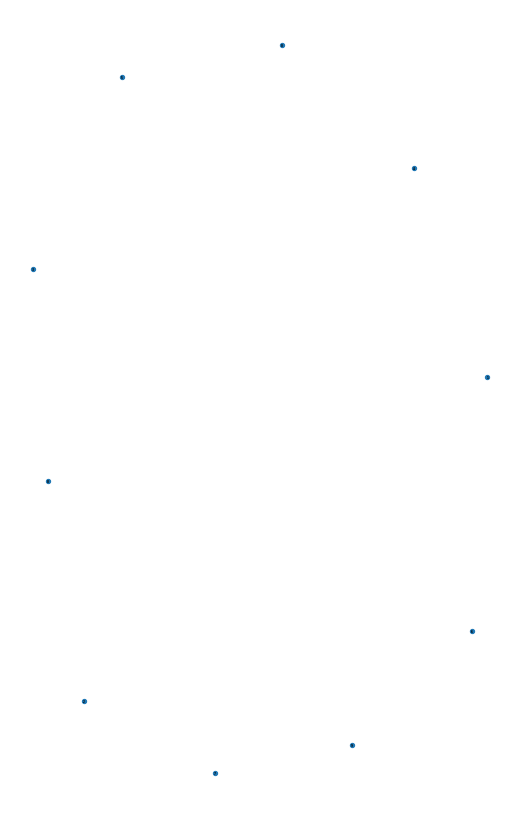

In [13]:
# Obtener el subgrafo inducido de los nodos 0 a 9 en el Snapshot 0
g_sub = graphs[0].subgraph(range(min(10, num_nodes))).copy()

# Calcular distribución espacial
pos = nx.spring_layout(g_sub, seed=42)

# Dibujar con el estilo exacto de la imagen de referencia
plt.figure(figsize=(5, 8), facecolor="white")
nx.draw(
    g_sub,
    pos,
    with_labels=True,
    node_color="#1f77b4",     # Color azul estándar de la imagen
    node_size=8,            # Nodos grandes
    font_weight="bold",       # Texto en negrita
    font_size=2,             # Letra grande
    font_color="black",       # Texto negro dentro de los nodos
    width=0.5,                # Aristas gruesas y negras
    edge_color="black"
)
plt.axis("off")
plt.tight_layout()
plt.show()

### Usuarios del Departamento 1
Todos los usuarios de este archivo pertenecen a Dept1. Se conserva su ID local y no se cruza con IDs de la red completa.


In [14]:
df_investigators_depts = pd.DataFrame({
    "Investigador_ID": original_node_ids,
    "Indice_Matriz": range(num_nodes),
    "Departamento_Principal": "Departamento 1",
})
for g in graphs:
    nx.set_node_attributes(g, {i: int(u) for i, u in enumerate(original_node_ids)}, "original_id")
    nx.set_node_attributes(g, "Departamento 1", "departamento")
df_investigators_depts.to_csv("data/TemporalEmail/investigador_departamento_dept1.csv", index=False)
print(df_investigators_depts["Departamento_Principal"].value_counts())


Departamento_Principal
Departamento 1    309
Name: count, dtype: int64


## Configuración del experimento
`FIXED_CLUSTER_COUNTS` fija los cortes comunes antes de inspeccionar resultados. Los valores 5, 10 y 20 son exploratorios, no una elección óptima. Cambiarlos no obliga a repetir las jerarquías guardadas. El baseline se calcula una vez: su desempate es determinista, repetirlo no aporta variabilidad de partición.

El tiempo corresponde a construir la jerarquía completa (n−1 fusiones), no al tiempo de detenerse en el corte. Se excluyen carga, preparación de grafos, tablas y figuras. Los tiempos recuperados de disco pertenecen a la ejecución original. Las semillas 42–51 se emparejan entre B=10 y B=40.

In [15]:
import hashlib
import json
from itertools import combinations
from scipy.optimize import linear_sum_assignment
from IPython.display import display

FIXED_CLUSTER_COUNTS = [5, 10, 20]
NUM_RUNS = 10
EXPERIMENT_B_VALUES = [10, 40]
EXPERIMENT_PROJECTIONS = 5
FIRST_SEED = 42
FORCE_RECOMPUTE = False
RESULTS_ROOT = Path('data/TemporalEmail/resultados_dept1/cortes_fijos')
assert all(isinstance(k, int) and 1 <= k < len(graphs) for k in FIXED_CLUSTER_COUNTS)
assert len(set(FIXED_CLUSTER_COUNTS)) == len(FIXED_CLUSTER_COUNTS)


## Dispersión de las capas
Se mide densidad sobre todos los usuarios y también sobre los usuarios activos, para separar la escasez de actividad de la conectividad entre participantes. Una alta dispersión es compatible con proyecciones poco discriminativas y sensibilidad a la aleatoriedad, pero estas tablas por sí solas no prueban esa relación causal. El efecto regularizador observado para B en Test 2 no debe trasladarse automáticamente a este conjunto.

,count,mean,std,min,25%,50%,75%,max
active_users,1000.0,10.755000,10.349400,2.000000,3.000000,7.500000,15.000000,70.000000
edges,1000.0,7.424000,8.975901,1.000000,2.000000,4.000000,10.000000,67.000000
interactions,1000.0,8.539000,10.074322,1.000000,2.000000,5.000000,12.000000,79.000000
density_global,1000.0,0.000156,0.000189,0.000021,0.000042,0.000084,0.000210,0.001408
density_active,1000.0,0.378108,0.371913,0.027499,0.089164,0.190476,0.666667,1.000000
isolated_fraction,1000.0,0.965194,0.033493,0.773463,0.951456,0.975728,0.990291,0.993528


Capas con una sola arista: 23.70%
Horas vacías del intervalo: 1366


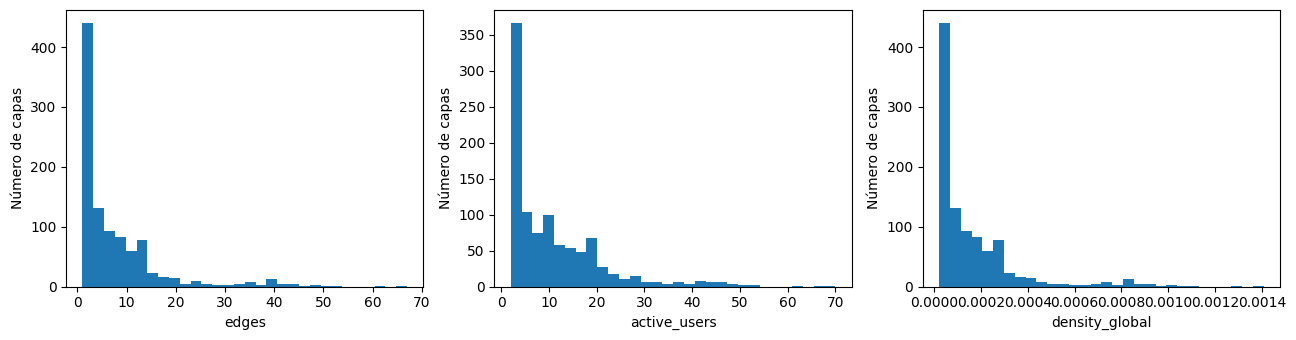

In [16]:
layer_records = []
for i, g in enumerate(graphs):
    active_count = sum(d > 0 for _, d in g.degree())
    edge_count = g.number_of_edges()
    layer_records.append(dict(layer=i, absolute_hour=g.graph['absolute_hour'],
        day=g.graph['day'], hour=g.graph['hour'], active_users=active_count,
        edges=edge_count, interactions=sum(d.get('weight', 1.) for _, _, d in g.edges(data=True)),
        density_global=nx.density(g),
        density_active=2*edge_count/(active_count*(active_count-1)) if active_count > 1 else 0,
        isolated_fraction=1-active_count/g.number_of_nodes()))
layer_features = pd.DataFrame(layer_records)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
# Los archivos de cada experimento se guardarán bajo una firma de datos e implementación.
display(layer_features.drop(columns=['layer', 'absolute_hour', 'day', 'hour']).describe().T)
print(f"Capas con una sola arista: {(layer_features.edges == 1).mean():.2%}")
print(f"Horas vacías del intervalo: {selection_metadata['end_hour_exclusive']-selection_metadata['start_hour']-len(graphs)}")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ['edges', 'active_users', 'density_global']):
    ax.hist(layer_features[col], bins=30)
    ax.set(xlabel=col, ylabel='Número de capas')
fig.tight_layout()
plt.show()


## Jerarquías reproducibles y reanudables
Se ejecuta una jerarquía baseline y diez por cada B (21 en total). Cada archivo contiene fusiones, q, semilla, buckets y tiempo. No se importan las curvas antiguas sin membresías. Las corridas terminadas se reutilizan tras una interrupción; la corrida interrumpida se reinicia. El fingerprint incluye datos, pesos, orden, código y versiones de las bibliotecas.

In [17]:
import scipy
notebook_path = Path('shclust-temporal-email-dept1.ipynb')
engine_source = ''.join(json.loads(notebook_path.read_text())['cells'][1]['source'])
h = hashlib.sha256(engine_source.encode())
h.update(repr(('fixed-cuts-v1', EXPERIMENT_PROJECTIONS, np.__version__, nx.__version__, scipy.__version__)).encode())
for g in graphs:
    h.update(repr((tuple(sorted(g.nodes())), g.graph.get('absolute_hour'),
        sorted((min(u,v), max(u,v), float(d.get('weight',1))) for u,v,d in g.edges(data=True)))).encode())
experiment_dir = RESULTS_ROOT / h.hexdigest()[:20]
experiment_dir.mkdir(parents=True, exist_ok=True)
layer_features.to_csv(experiment_dir/'layer_features.csv', index=False)
(experiment_dir/'selection.json').write_text(json.dumps(selection_metadata, indent=2))
(experiment_dir/'analysis_config.json').write_text(json.dumps(dict(
    cluster_counts=FIXED_CLUSTER_COUNTS, B_values=EXPERIMENT_B_VALUES,
    seeds=list(range(FIRST_SEED, FIRST_SEED+NUM_RUNS)), projections=EXPERIMENT_PROJECTIONS,
    numpy_version=np.__version__, networkx_version=nx.__version__, scipy_version=scipy.__version__), indent=2))
layer_features.drop(columns=['layer','absolute_hour','day','hour']).describe().T.to_csv(experiment_dir/'sparsity_summary.csv')

def validate_trajectory(z, n):
    if z.shape != (n-1, 5) or not np.isfinite(z).all():
        raise ValueError('Jerarquía incompleta o no finita')
    active = set(range(n))
    for step, row in enumerate(z):
        i, j, new = int(row[0]), int(row[1]), int(row[4])
        if row[0] != i or row[1] != j or row[4] != new or i == j or i not in active or j not in active or new != n+step:
            raise ValueError('Fusiones incompatibles con el orden de las capas')
        active.difference_update([i,j]); active.add(new)

def run_fixed_hierarchy(method, seed, B=None):
    tag = 'baseline' if method == 'baseline' else f'LSH_B{B}'
    checkpoint = experiment_dir/f'{tag}_seed{seed}.npz'
    reused = checkpoint.exists() and not FORCE_RECOMPUTE
    if reused:
        with np.load(checkpoint, allow_pickle=False) as saved:
            z = saved['z'].copy()
            row = json.loads(str(saved['metadata'].item()))
        if (row['method'], row['B'], row['seed']) != (method, B, seed):
            raise ValueError('Configuración incompatible en checkpoint')
        print(f'{tag}, semilla {seed}: recuperado')
    else:
        inputs = fresh_graphs(graphs)
        numpy_state, python_state = np.random.get_state(), random.getstate()
        try:
            np.random.seed(seed); random.seed(seed)
            begin = time.perf_counter()
            if method == 'baseline':
                raw, _, _ = hierarchical_clustering_heap(inputs)
                elapsed = time.perf_counter()-begin
                buckets, restricted, global_merges = None, 0, len(raw)
            else:
                raw, _, _, _, ids = shclust_heap_dynamic(inputs, num_proj=EXPERIMENT_PROJECTIONS, B=B)
                elapsed = time.perf_counter()-begin
                buckets = len(set(ids))
                global_merges = sum(bool(r[7]) for r in raw)
                restricted = len(raw)-global_merges
            z = np.asarray([r[:5] for r in raw], dtype=float)
            row = dict(method=method, B=B, seed=seed, initial_buckets=buckets,
                       restricted_merges=restricted, global_merges=global_merges,
                       full_hierarchy_seconds=elapsed)
        finally:
            np.random.set_state(numpy_state); random.setstate(python_state)
        validate_trajectory(z, len(graphs))
        temporary = checkpoint.with_suffix('.tmp.npz')
        np.savez_compressed(temporary, z=z, metadata=json.dumps(row))
        temporary.replace(checkpoint)
    validate_trajectory(z, len(graphs))
    return dict(z=z, metadata=row, reused=reused)


In [18]:
baseline_run = run_fixed_hierarchy('baseline', FIRST_SEED)
lsh_runs = {}
for B in EXPERIMENT_B_VALUES:
    lsh_runs[B] = []
    for seed in range(FIRST_SEED, FIRST_SEED+NUM_RUNS):
        print(f'LSH B={B}, semilla={seed}', flush=True)
        lsh_runs[B].append(run_fixed_hierarchy('LSH', seed, B))
print('Jerarquías disponibles:', 1+sum(map(len, lsh_runs.values())))


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [43:37<00:00,  2.62s/it]

LSH B=10, semilla=42



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [33:42<00:00,  2.02s/it]

LSH B=10, semilla=43



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [33:27<00:00,  2.01s/it]

...

LSH B=40, semilla=50


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [36:51<00:00,  2.21s/it]


LSH B=40, semilla=51


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [36:52<00:00,  2.21s/it]


Jerarquías disponibles: 21


## Tablas a cortes fijos y variabilidad de las particiones
Para K clusters se aplican exactamente n−K fusiones y se consulta q en la fila n−K−1. El número de clusters y el paso serán iguales por diseño; la variabilidad se estudia en calidad, tamaños y membresías.

Se compara la fracción de capas coincidentes tras emparejar los clusters uno a uno maximizando el solapamiento. Es una descripción sin corrección por azar y puede estar dominada por un cluster grande. Se muestran también tamaños y matrices de solapamiento; no se interpreta esta fracción como exactitud frente a una verdad de terreno. Las 45 parejas entre semillas de cada B no son observaciones independientes.

In [19]:
def labels_at_fixed_cut(z, n, k):
    validate_trajectory(z, n)
    merges = n-k
    if not 1 <= k < n:
        raise ValueError('Se requiere 1 <= K < número de capas')
    members = get_cluster_memberships(z, n, merges)
    labels = np.empty(n, dtype=int)
    # IDs reproducibles: orden por primera capa miembro.
    for label, items in enumerate(sorted(members.values(), key=min)):
        labels[items] = label
    assert len(np.unique(labels)) == k
    return labels, float(z[merges-1, 3])

def overlap_table(a, b):
    table = pd.crosstab(pd.Series(a, name='Baseline/partición A'), pd.Series(b, name='Partición B'))
    rows, cols = linear_sum_assignment(-table.to_numpy())
    matched = table.to_numpy()[rows, cols].sum()/len(a)
    return table, float(matched)

all_runs = [baseline_run]+[run for B in EXPERIMENT_B_VALUES for run in lsh_runs[B]]
cut_rows, assignments, cluster_profiles, overlaps = [], {}, [], []
for k in FIXED_CLUSTER_COUNTS:
    base_labels, base_q = labels_at_fixed_cut(baseline_run['z'], len(graphs), k)
    for run in all_runs:
        meta = run['metadata']
        tag = 'baseline' if meta['method']=='baseline' else f"LSH_B{meta['B']}"
        labels, q_cut = labels_at_fixed_cut(run['z'], len(graphs), k)
        assignments[(tag, meta['seed'], k)] = labels
        sizes = np.bincount(labels)
        _, matched = overlap_table(base_labels, labels)
        cut_rows.append(dict(**meta, K=k, aggregation_steps=len(graphs)-k, q_at_cut=q_cut,
            q_difference_vs_baseline=q_cut-base_q, matched_fraction_vs_baseline=matched,
            smallest_cluster=int(sizes.min()), largest_cluster=int(sizes.max()),
            largest_cluster_fraction=float(sizes.max()/len(graphs)), singleton_clusters=int((sizes==1).sum()),
            speedup_vs_baseline=baseline_run['metadata']['full_hierarchy_seconds']/meta['full_hierarchy_seconds']))
        activity = layer_features.assign(cluster=labels)
        prefix = f"{tag}_seed{meta['seed']}_K{k}"
        activity.to_csv(experiment_dir/f'{prefix}_memberships.csv', index=False)
        profiles = activity.groupby('cluster').agg(layers=('layer','size'),
            mean_users=('active_users','mean'), median_users=('active_users','median'),
            mean_edges=('edges','mean'), median_interactions=('interactions','median'),
            total_interactions=('interactions','sum'), mean_density=('density_global','mean'),
            first_day=('day','min'), last_day=('day','max')).reset_index()
        profiles['method'] = tag; profiles['seed'] = meta['seed']; profiles['K'] = k
        cluster_profiles.append(profiles)
    for B in EXPERIMENT_B_VALUES:
        for a, b in combinations(lsh_runs[B], 2):
            sa, sb = a['metadata']['seed'], b['metadata']['seed']
            _, matched = overlap_table(assignments[(f'LSH_B{B}', sa, k)], assignments[(f'LSH_B{B}', sb, k)])
            overlaps.append(dict(B=B, K=k, seed_a=sa, seed_b=sb, matched_fraction=matched))
cut_results = pd.DataFrame(cut_rows)
profile_results = pd.concat(cluster_profiles, ignore_index=True)
pairwise_results = pd.DataFrame(overlaps)
cut_results.to_csv(experiment_dir/'fixed_cut_runs.csv', index=False)
profile_results.to_csv(experiment_dir/'cluster_profiles_all_runs.csv', index=False)
pairwise_results.to_csv(experiment_dir/'pairwise_membership_overlap.csv', index=False)
metrics = ['q_at_cut','q_difference_vs_baseline','initial_buckets','full_hierarchy_seconds',
           'matched_fraction_vs_baseline','largest_cluster_fraction','singleton_clusters']
summary_fixed = cut_results.groupby(['method','B','K'], dropna=False)[metrics].agg(['mean','std','min','max'])
summary_fixed.to_csv(experiment_dir/'fixed_cut_summary.csv')
display(cut_results)
display(summary_fixed)
if not pairwise_results.empty:
    display(pairwise_results.groupby(['B','K']).matched_fraction.agg(['mean','std','min','max']))
print('La desviación estándar del baseline es NaN porque solo se ejecuta una vez.')

observations = [f"Dept1: {len(graphs)} capas, {graphs[0].number_of_nodes()} usuarios por capa.",
    f"Mediana de aristas/capa: {layer_features.edges.median():.1f}; "
    f"mediana de usuarios activos: {layer_features.active_users.median():.1f}; "
    f"mediana de densidad global: {layer_features.density_global.median():.6f}.",
    f"Capas con una sola arista: {(layer_features.edges==1).mean():.2%}."]
for k in FIXED_CLUSTER_COUNTS:
    for B in EXPERIMENT_B_VALUES:
        t = cut_results[(cut_results.K==k)&(cut_results.B==B)]
        observations.append(f"K={k}, B={B}: q={t.q_at_cut.mean():.6f} ± {t.q_at_cut.std():.6f} "
            f"(media ± DE); coincidencia con baseline={t.matched_fraction_vs_baseline.mean():.1%}; "
            f"fracción del mayor cluster={t.largest_cluster_fraction.mean():.1%}; "
            f"buckets iniciales={t.initial_buckets.mean():.1f} ± {t.initial_buckets.std():.1f}.")
observations.append("La coincidencia no está corregida por azar. Ver perfiles y solapamientos antes de interpretar los grupos. "
    "Los cortes son exploratorios y no se seleccionan maximizando q. La dispersión no demuestra por sí sola la causa de la variabilidad.")
(experiment_dir/'observed_results.txt').write_text('\n'.join(observations))
print('\n'.join(observations))


,method,B,seed,initial_buckets,restricted_merges,global_merges,full_hierarchy_seconds,K,aggregation_steps,q_at_cut,q_difference_vs_baseline,matched_fraction_vs_baseline,smallest_cluster,largest_cluster,largest_cluster_fraction,singleton_clusters,speedup_vs_baseline
0,baseline,NaN,42,NaN,0,999,3173.466516,5,995,0.633211,0.000000,1.000,1,996,0.996,4,1.000000
1,LSH,10.0,42,712.0,288,711,2025.392964,5,995,0.467121,-0.166090,0.992,1,994,0.994,3,1.566840
2,LSH,10.0,43,717.0,283,716,2011.629939,5,995,0.510983,-0.122228,0.991,1,995,0.995,3,1.577560
3,LSH,10.0,44,726.0,274,725,2104.344730,5,995,0.451625,-0.181586,0.988,1,992,0.992,3,1.508054
4,LSH,10.0,45,720.0,280,719,2045.227498,5,995,0.506785,-0.126425,0.991,1,995,0.995,3,1.551645
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,LSH,40.0,47,759.0,241,758,2250.564446,20,980,0.659665,-0.172917,0.938,1,937,0.937,8,1.410076
59,LSH,40.0,48,752.0,248,751,2211.706468,20,980,0.600946,-0.231636,0.912,1,929,0.929,8,1.434850
60,LSH,40.0,49,753.0,247,752,2213.424160,20,980,0.638283,-0.194299,0.928,1,940,0.940,7,1.433736
61,LSH,40.0,50,743.0,257,742,2215.133077,20,980,0.683467,-0.149115,0.938,1,944,0.944,11,1.432630


q_at_cut                                \
                      mean       std       min       max   
method   B    K                                            
LSH      10.0 5   0.487881  0.022751  0.451625  0.513761   
              10  0.602999  0.027095  0.541793  0.637991   
              20  0.637141  0.021937  0.594293  0.664807   
         40.0 5   0.490032  0.023125  0.466665  0.531416   
              10  0.609537  0.019540  0.582010  0.637991   
              20  0.645006  0.023923  0.600946  0.683467   
baseline NaN  5   0.633211       NaN  0.633211  0.633211   
              10  0.805682       NaN  0.805682  0.805682   
              20  0.832582       NaN  0.832582  0.832582   

                 q_difference_vs_baseline                                \
                                     mean       std       min       max   
method   B    K                                                           
LSH      10.0 5                 -0.145330  0.022751 -0.181586 -0.119450   
              10                -0.202683  0.027095 -0.263889 -0.167691   
              20                -0.195441  0.021937 -0.238289 -0.167775   
         40.0 5                 -0.143179  0.023125 -0.166546 -0.101795   
              10                -0.196146  0.019540 -0.223673 -0.167691   
              20                -0.187576  0.023923 -0.231636 -0.149115   
baseline NaN  5                  0.000000       NaN  0.000000  0.000000   
              10                 0.000000       NaN  0.000000  0.000000   
              20                 0.000000       NaN  0.000000  0.000000   

                 initial_buckets            ... matched_fraction_vs_baseline  \
                            mean       std  ...                          min   
method   B    K                             ...                                
LSH      10.0 5            721.0  6.582806  ...                        0.983   
              10           721.0  6.582806  ...                        0.966   
              20           721.0  6.582806  ...                        0.917   
         40.0 5            752.1  6.100091  ...                        0.983   
              10           752.1  6.100091  ...                        0.963   
              20           752.1  6.100091  ...                        0.912   
baseline NaN  5              NaN       NaN  ...                        1.000   
              10             NaN       NaN  ...                        1.000   
              20             NaN       NaN  ...                        1.000   

                        largest_cluster_fraction                          \
                    max                     mean       std    min    max   
method   B    K                                                            
LSH      10.0 5   0.993                   0.9927  0.003057  0.987  0.996   
              10  0.981                   0.9795  0.006416  0.969  0.988   
              20  0.941                   0.9424  0.009879  0.929  0.959   
         40.0 5   0.993                   0.9929  0.003213  0.987  0.996   
              10  0.980                   0.9789  0.006154  0.966  0.986   
              20  0.940                   0.9455  0.010047  0.929  0.960   
baseline NaN  5   1.000                   0.9960       NaN  0.996  0.996   
              10  1.000                   0.9890       NaN  0.989  0.989   
              20  1.000                   0.9640       NaN  0.964  0.964   

                 singleton_clusters                    
                               mean       std min max  
method   B    K                                        
LSH      10.0 5                 2.9  0.567646   2   4  
              10                5.0  1.247219   3   7  
              20                7.7  0.948683   6   9  
         40.0 5                 3.0  0.666667   2   4  
              10                5.2  0.918937   3   6  
              20                8.5  1.269296   7  11  
baseline NaN  5   

mean       std    min    max
B  K                                   
10 5   0.987533  0.004336  0.976  0.995
   10  0.964800  0.008086  0.946  0.982
   20  0.914156  0.010583  0.887  0.936
40 5   0.988200  0.004511  0.975  0.995
   10  0.964533  0.008165  0.943  0.983
   20  0.919378  0.011653  0.888  0.948

La desviación estándar del baseline es NaN porque solo se ejecuta una vez.
Dept1: 1000 capas, 309 usuarios por capa.
Mediana de aristas/capa: 4.0; mediana de usuarios activos: 7.5; mediana de densidad global: 0.000084.
Capas con una sola arista: 23.70%.
K=5, B=10: q=0.487881 ± 0.022751 (media ± DE); coincidencia con baseline=98.9%; fracción del mayor cluster=99.3%; buckets iniciales=721.0 ± 6.6.
K=5, B=40: q=0.490032 ± 0.023125 (media ± DE); coincidencia con baseline=99.0%; fracción del mayor cluster=99.3%; buckets iniciales=752.1 ± 6.1.
K=10, B=10: q=0.602999 ± 0.027095 (media ± DE); coincidencia con baseline=97.3%; fracción del mayor cluster=98.0%; buckets iniciales=721.0 ± 6.6.
K=10, B=40: q=0.609537 ± 0.019540 (media ± DE); coincidencia con baseline=97.2%; fracción del mayor cluster=97.9%; buckets iniciales=752.1 ± 6.1.
K=20, B=10: q=0.637141 ± 0.021937 (media ± DE); coincidencia con baseline=93.0%; fracción del mayor cluster=94.2%; buckets iniciales=721.0 ± 6.6.
K=20, B=40: q=0.64

## Diez curvas de q(C) por B y comparación con baseline
Cada panel contiene todas las semillas y el baseline. Las líneas verticales indican cortes previamente fijados, no codos ni máximos. Un segundo panel muestra q al corte por semilla para comparar B con las mismas proyecciones aleatorias.

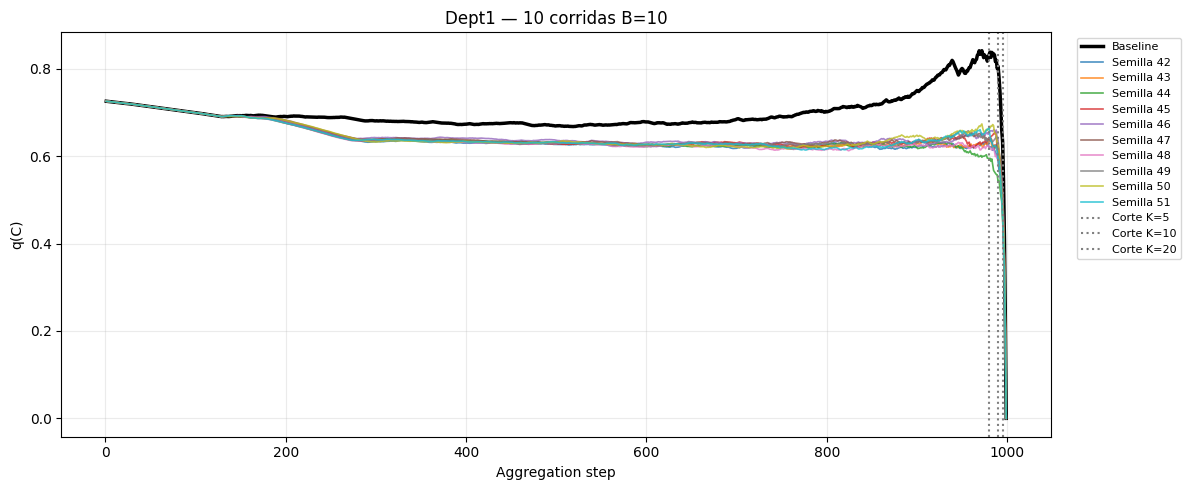

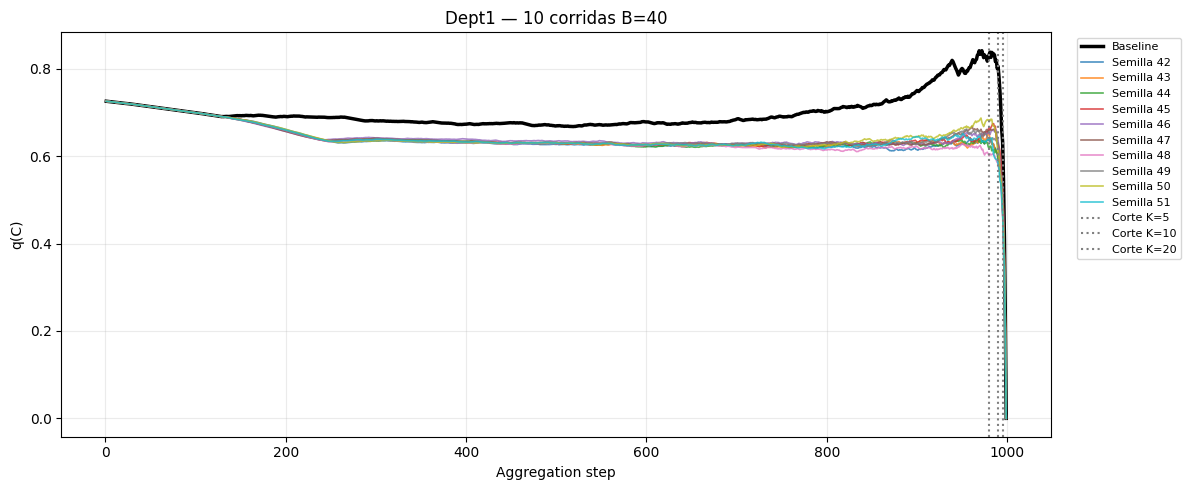

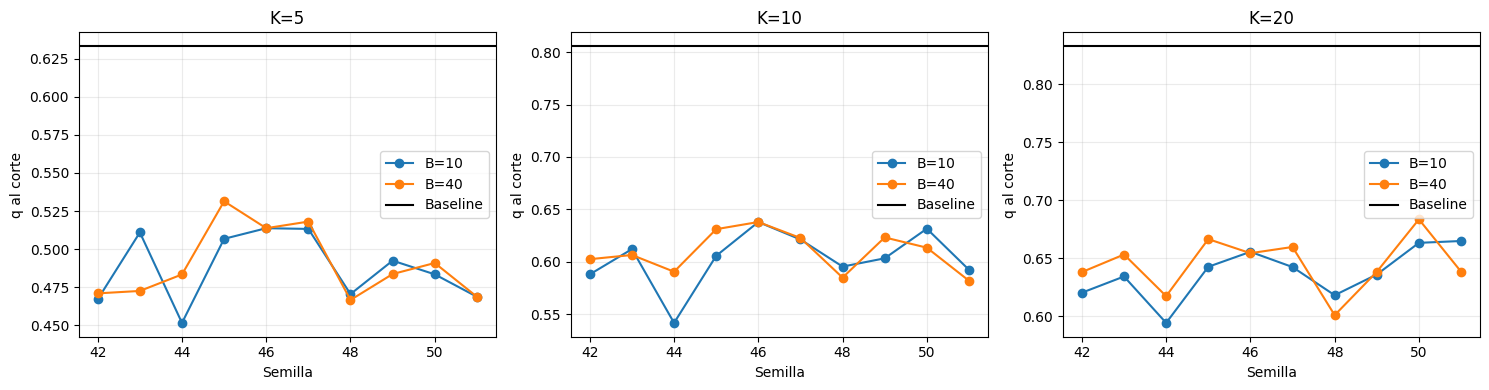

In [20]:
for B in EXPERIMENT_B_VALUES:
    fig, ax = plt.subplots(figsize=(12, 5))
    steps = np.arange(1, len(graphs))
    ax.plot(steps, baseline_run['z'][:,3], color='black', lw=2.5, label='Baseline')
    curves = {'aggregation_step':steps, 'baseline':baseline_run['z'][:,3]}
    for r, run in enumerate(lsh_runs[B]):
        seed = run['metadata']['seed']
        ax.plot(steps, run['z'][:,3], alpha=.8, lw=1.2, label=f'Semilla {seed}')
        curves[f'seed_{seed}'] = run['z'][:,3]
    for k in FIXED_CLUSTER_COUNTS:
        ax.axvline(len(graphs)-k, ls=':', color='gray', label=f'Corte K={k}')
    ax.set(xlabel='Aggregation step', ylabel='q(C)', title=f'Dept1 — {NUM_RUNS} corridas B={B}')
    ax.grid(alpha=.25); ax.legend(bbox_to_anchor=(1.02,1), loc='upper left', fontsize=8)
    fig.tight_layout()
    for extension in ['png','pdf']:
        fig.savefig(experiment_dir/f'quality_B{B}.{extension}', bbox_inches='tight')
    pd.DataFrame(curves).to_csv(experiment_dir/f'quality_B{B}.csv', index=False)
    plt.show()
fig, axes = plt.subplots(1, len(FIXED_CLUSTER_COUNTS), figsize=(5*len(FIXED_CLUSTER_COUNTS),4), squeeze=False)
for ax, k in zip(axes[0], FIXED_CLUSTER_COUNTS):
    for B in EXPERIMENT_B_VALUES:
        table = cut_results[(cut_results.B==B)&(cut_results.K==k)]
        ax.plot(table.seed, table.q_at_cut, 'o-', label=f'B={B}')
    base = cut_results[(cut_results.method=='baseline')&(cut_results.K==k)].q_at_cut.iloc[0]
    ax.axhline(base, color='black', label='Baseline')
    ax.set(title=f'K={k}', xlabel='Semilla', ylabel='q al corte'); ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(experiment_dir/'quality_fixed_cuts.png', dpi=180)
plt.show()


## Interpretación de los grupos
Se exportan perfiles y membresías de todas las corridas. Para las figuras detalladas se usa la semilla 42, fijada de antemano, sin elegir la curva más favorable. Los colores/IDs son locales a cada partición; un mismo color no significa el mismo cluster entre métodos. Gris indica horas sin actividad y blanco posiciones fuera del intervalo.

Para valorar si los grupos tienen sentido se examinan tamaños, distribución día × hora, usuarios, aristas e intensidad de actividad; además se listan participantes y conexiones recurrentes. Un cluster dominado por capas de una sola arista puede reflejar dispersión y repetición de contactos, no una comunidad. Todos los usuarios pertenecen a Dept1: el departamento no valida la partición. Las observaciones son descriptivas, sin etiquetas externas de verdad.

In [21]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


def layer_activity_table(graphs, labels):
    """Department participation counts message endpoints (two per interaction)."""
    if len(graphs) != len(labels):
        raise ValueError("Se requiere una etiqueta por capa")
    rows, profiles = [], []
    for layer, (g, cluster) in enumerate(zip(graphs, labels)):
        active = [u for u, degree in g.degree() if degree > 0]
        departments = {u: str(g.nodes[u].get('departamento', 'Otros')).strip() or 'Otros'
                       for u in active}
        participation = defaultdict(float)
        events = internal = external = unknown = 0.0
        for u, v, data in g.edges(data=True):
            w = float(data.get('weight', 1))
            events += w
            a, b = departments[u], departments[v]
            participation[a] += w
            participation[b] += w
            if 'Otros' in (a, b):
                unknown += w
            elif a == b:
                internal += w
            else:
                external += w
        total = sum(participation.values())
        known = {d: w for d, w in participation.items() if d != 'Otros'}
        largest = max(known.values(), default=0)
        winners = sorted(d for d, w in known.items() if w == largest)
        dominant = winners[0] if len(winners) == 1 else ('Empate' if winners else 'Sin asignación')
        rows.append(dict(layer=layer, day=int(g.graph['day']), hour=int(g.graph['hour']),
                         cluster=int(cluster), active_users=len(active), interactions=events,
                         edges=g.number_of_edges(),
                         density=nx.density(g),
                         label_coverage=sum(d != 'Otros' for d in departments.values()) / len(active) if active else 0,
                         dominant_department=dominant,
                         dominant_share=largest / total if total else 0,
                         internal_interactions=internal, external_interactions=external,
                         unknown_department_interactions=unknown))
        for department, weight in participation.items():
            profiles.append(dict(layer=layer, cluster=int(cluster), department=department,
                                 participation=weight, share=weight / total if total else 0))
    return pd.DataFrame(rows), pd.DataFrame(profiles)


def temporal_cluster_grid(table, start_hour, end_hour):
    """-2 outside interval; -1 empty hour; nonnegative categorical cluster codes."""
    first_day, last_day = start_hour // 24, (end_hour - 1) // 24
    hours = np.arange(first_day * 24, (last_day + 1) * 24).reshape(-1, 24)
    grid = np.where((hours >= start_hour) & (hours < end_hour), -1, -2)
    cluster_ids = sorted(table.cluster.unique())
    codes = {cluster: i for i, cluster in enumerate(cluster_ids)}
    for row in table.itertuples():
        grid[row.day - first_day, row.hour] = codes[row.cluster]
    return grid, first_day, cluster_ids


def plot_temporal_analysis(graphs, labels, method, selection, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    table, profiles = layer_activity_table(graphs, labels)
    table.to_csv(output_dir / f'{method}_capas.csv', index=False)
    summary = table.groupby('cluster').agg(
        layers=('layer', 'size'), mean_active_users=('active_users', 'mean'),
        total_interactions=('interactions', 'sum'), mean_interactions=('interactions', 'mean'),
        mean_edges=('edges', 'mean'), mean_density=('density', 'mean'),
        mean_label_coverage=('label_coverage', 'mean'),
        internal_interactions=('internal_interactions', 'sum'),
        external_interactions=('external_interactions', 'sum'),
        unknown_department_interactions=('unknown_department_interactions', 'sum'))
    summary.to_csv(output_dir / f'{method}_clusters.csv')
    print(f'\nActividad por cluster — {method}')
    print(summary.to_string())

    grid, first_day, cluster_ids = temporal_cluster_grid(
        table, selection['start_hour'], selection['end_hour_exclusive'])
    palette = plt.get_cmap('tab20', max(1, len(cluster_ids)))
    colors = ['white', '#dedede'] + [palette(i) for i in range(len(cluster_ids))]
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(-2.5, len(cluster_ids) + .5), len(colors))
    fig, ax = plt.subplots(figsize=(13, max(5, min(16, len(grid) * .18))))
    ax.imshow(grid, cmap=cmap, norm=norm, aspect='auto', interpolation='nearest')
    ticks = np.unique(np.linspace(0, len(grid) - 1, min(20, len(grid)), dtype=int))
    ax.set_yticks(ticks, ticks + first_day)
    ax.set_xticks(range(24))
    ax.set(xlabel='Hora relativa', ylabel='Día relativo', title=f'Cluster por ventana horaria — {method}')
    handles = [Patch(facecolor=colors[0], edgecolor='gray', label='Fuera del intervalo'),
               Patch(facecolor=colors[1], label='Sin interacciones')]
    handles += [Patch(facecolor=colors[i + 2], label=f'Cluster {c}') for i, c in enumerate(cluster_ids)]
    ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    fig.tight_layout()
    fig.savefig(output_dir / f'{method}_dia_hora.png', dpi=180, bbox_inches='tight')
    plt.show()

    if profiles.empty or profiles.department.nunique() <= 1 or not (profiles.department != 'Otros').any():
        print('Perfil departamental omitido: Dept1 no permite distinguir departamentos.')
        return table, summary

    # Fill missing layer/department combinations with zero before averaging.
    shares = profiles.pivot(index='layer', columns='department', values='share').fillna(0)
    hourly = shares.groupby(table.set_index('layer')['cluster']).mean()
    totals = profiles.groupby(['cluster', 'department']).participation.sum().unstack(fill_value=0)
    weighted = totals.div(totals.sum(axis=1), axis=0)
    weighted = weighted.reindex(index=hourly.index, columns=hourly.columns, fill_value=0)
    hourly.to_csv(output_dir / f'{method}_departamentos_promedio_hora.csv')
    weighted.to_csv(output_dir / f'{method}_departamentos_ponderados.csv')
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(hourly) * .3)), constrained_layout=True)
    for ax, matrix, title in zip(axes, [hourly, weighted],
                                ['Igual peso por hora', 'Ponderado por interacciones']):
        im = ax.imshow(matrix.values, vmin=0, vmax=1, cmap='Blues', aspect='auto')
        ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha='right')
        ax.set_yticks(range(len(matrix)), matrix.index)
        ax.set(title=title, xlabel='Departamento', ylabel='Cluster')
    fig.colorbar(im, ax=axes, label='Proporción de participación (extremos de interacciones)')
    fig.suptitle(f'Perfil departamental — {method}')
    fig.savefig(output_dir / f'{method}_cluster_departamento.png', dpi=180, bbox_inches='tight')
    plt.show()
    return table, summary




Actividad por cluster — baseline_seed42_K5
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           996          10.790161              8535.0           8.569277    7.449799      0.000157                  1.0                 8535.0                    0.0                              0.0
1             1           2.000000                 1.0           1.000000    1.000000      0.000021                  1.0                    1.0                    0.0                              0.0
2             1           2.000000                 1.0           1.000000    1.000000      0.000021                  1.0                    1.0             

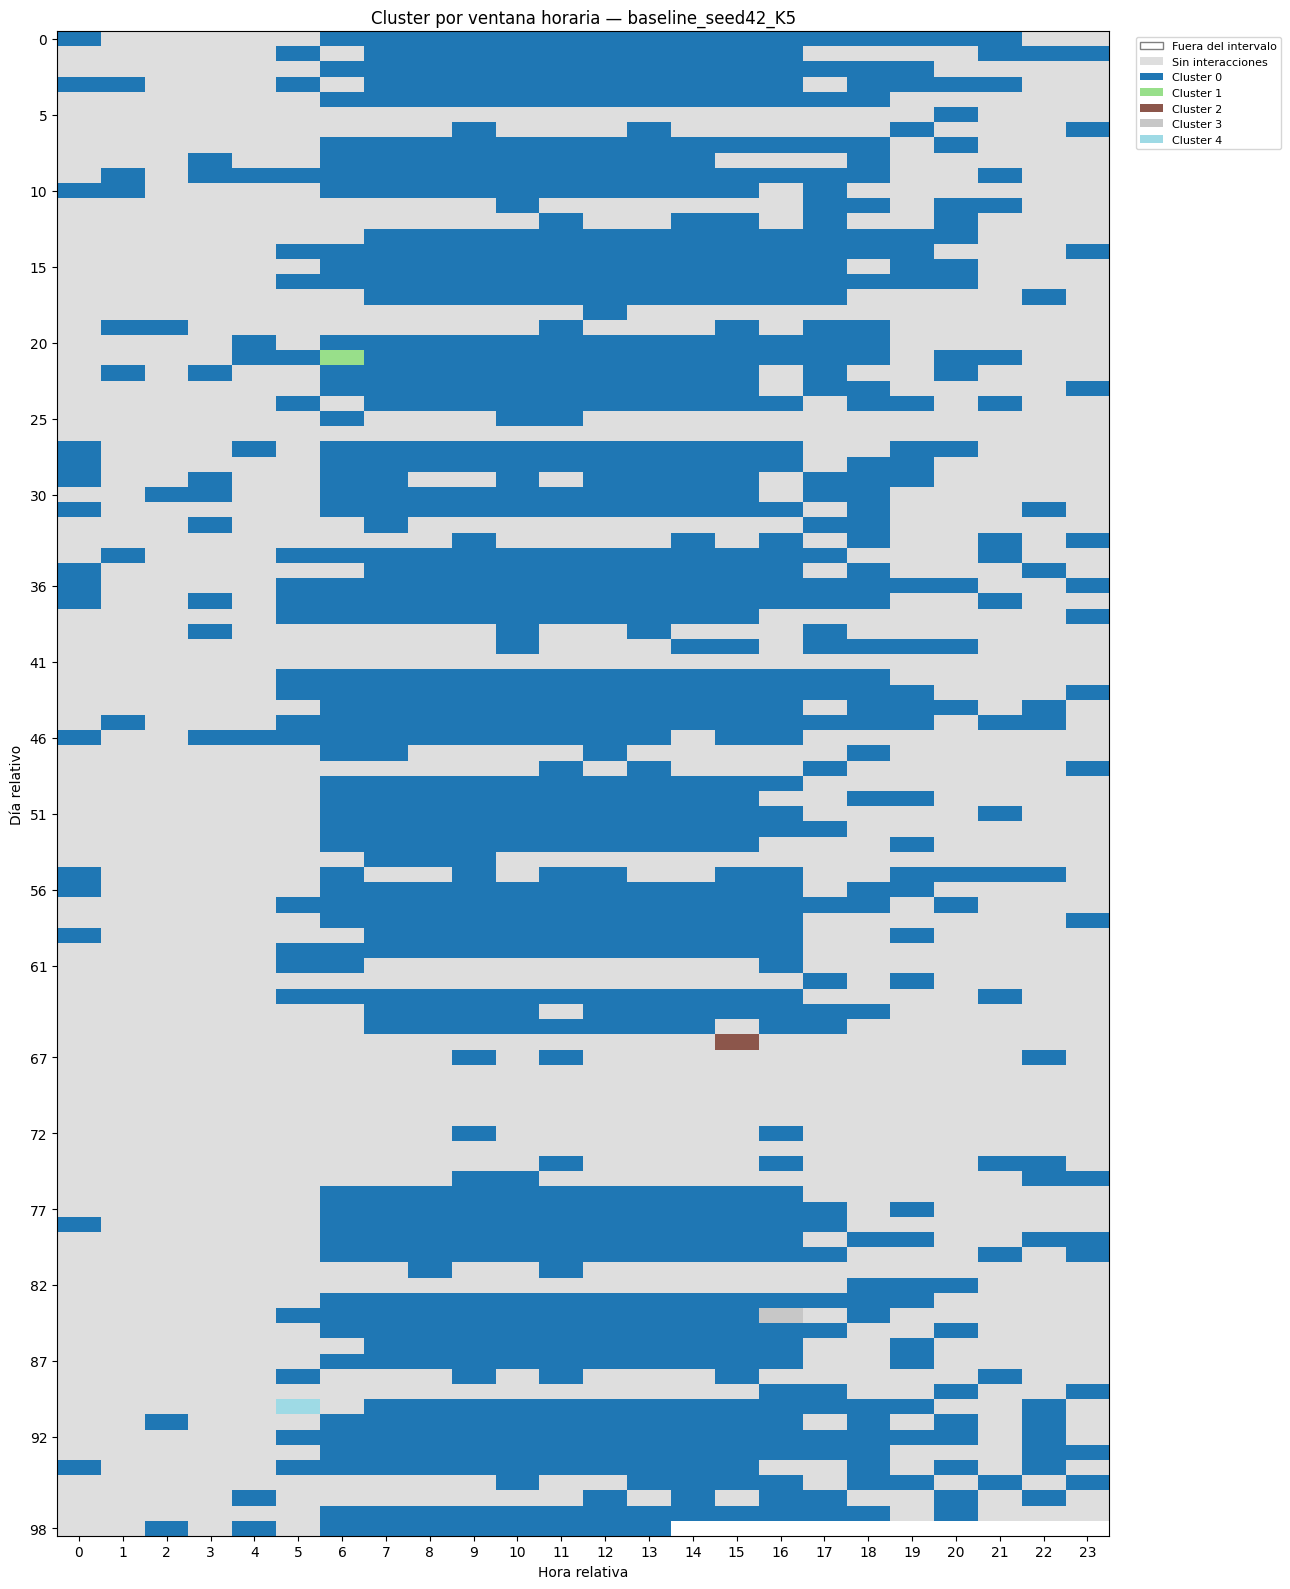

Perfil departamental omitido: Dept1 no permite distinguir departamentos.

Actividad por cluster — LSH_B10_seed42_K5
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           994          10.793763              8525.0           8.576459    7.455734      0.000157                  1.0                 8525.0                    0.0                              0.0
1             1           8.000000                 4.0           4.000000    4.000000      0.000084                  1.0                    4.0                    0.0                              0.0
2             3           2.000000                 3.0           1.000000    1.00000

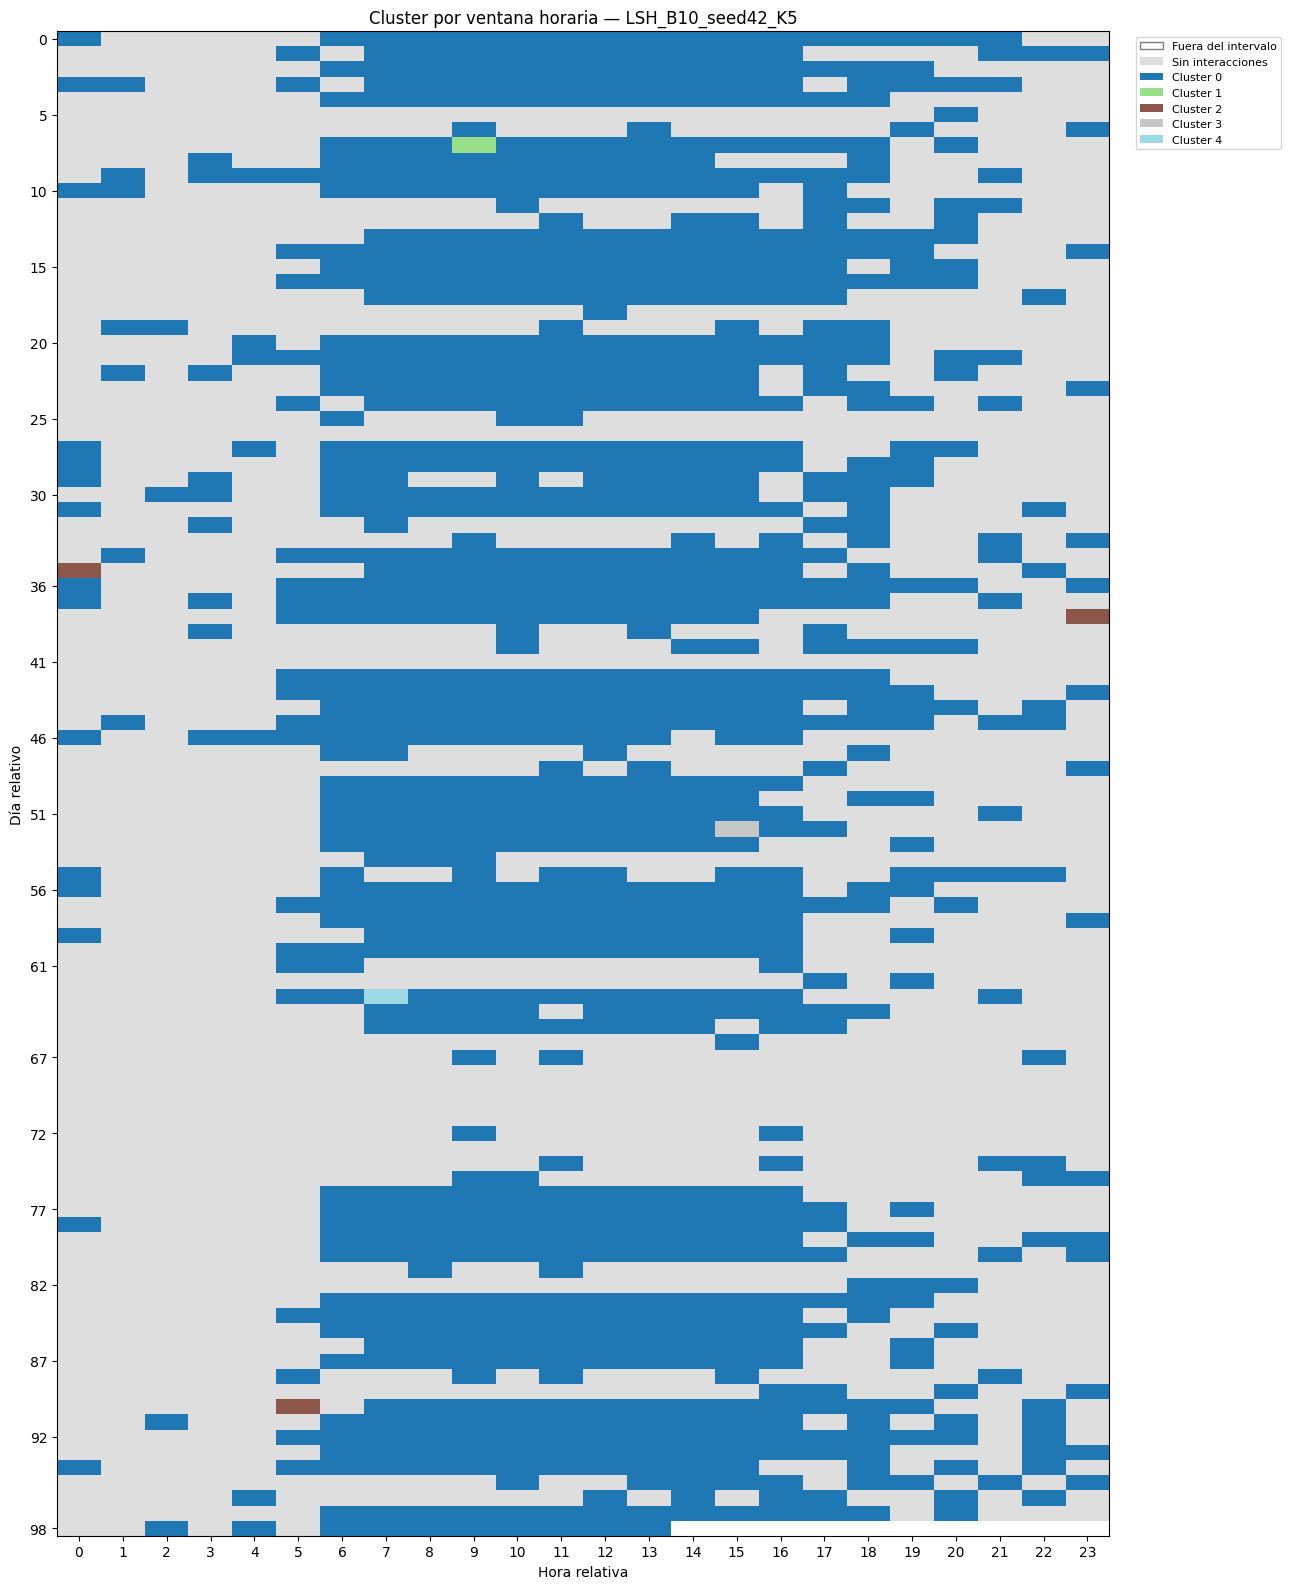

Perfil departamental omitido: Dept1 no permite distinguir departamentos.


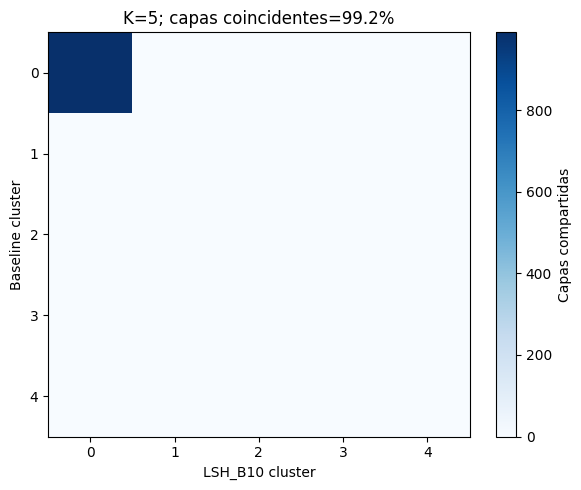


Actividad por cluster — LSH_B40_seed42_K5
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           994          10.794769              8525.0           8.576459    7.455734      0.000157                  1.0                 8525.0                    0.0                              0.0
1             1           8.000000                 4.0           4.000000    4.000000      0.000084                  1.0                    4.0                    0.0                              0.0
2             3           2.000000                 3.0           1.000000    1.000000      0.000021                  1.0                    3.0              

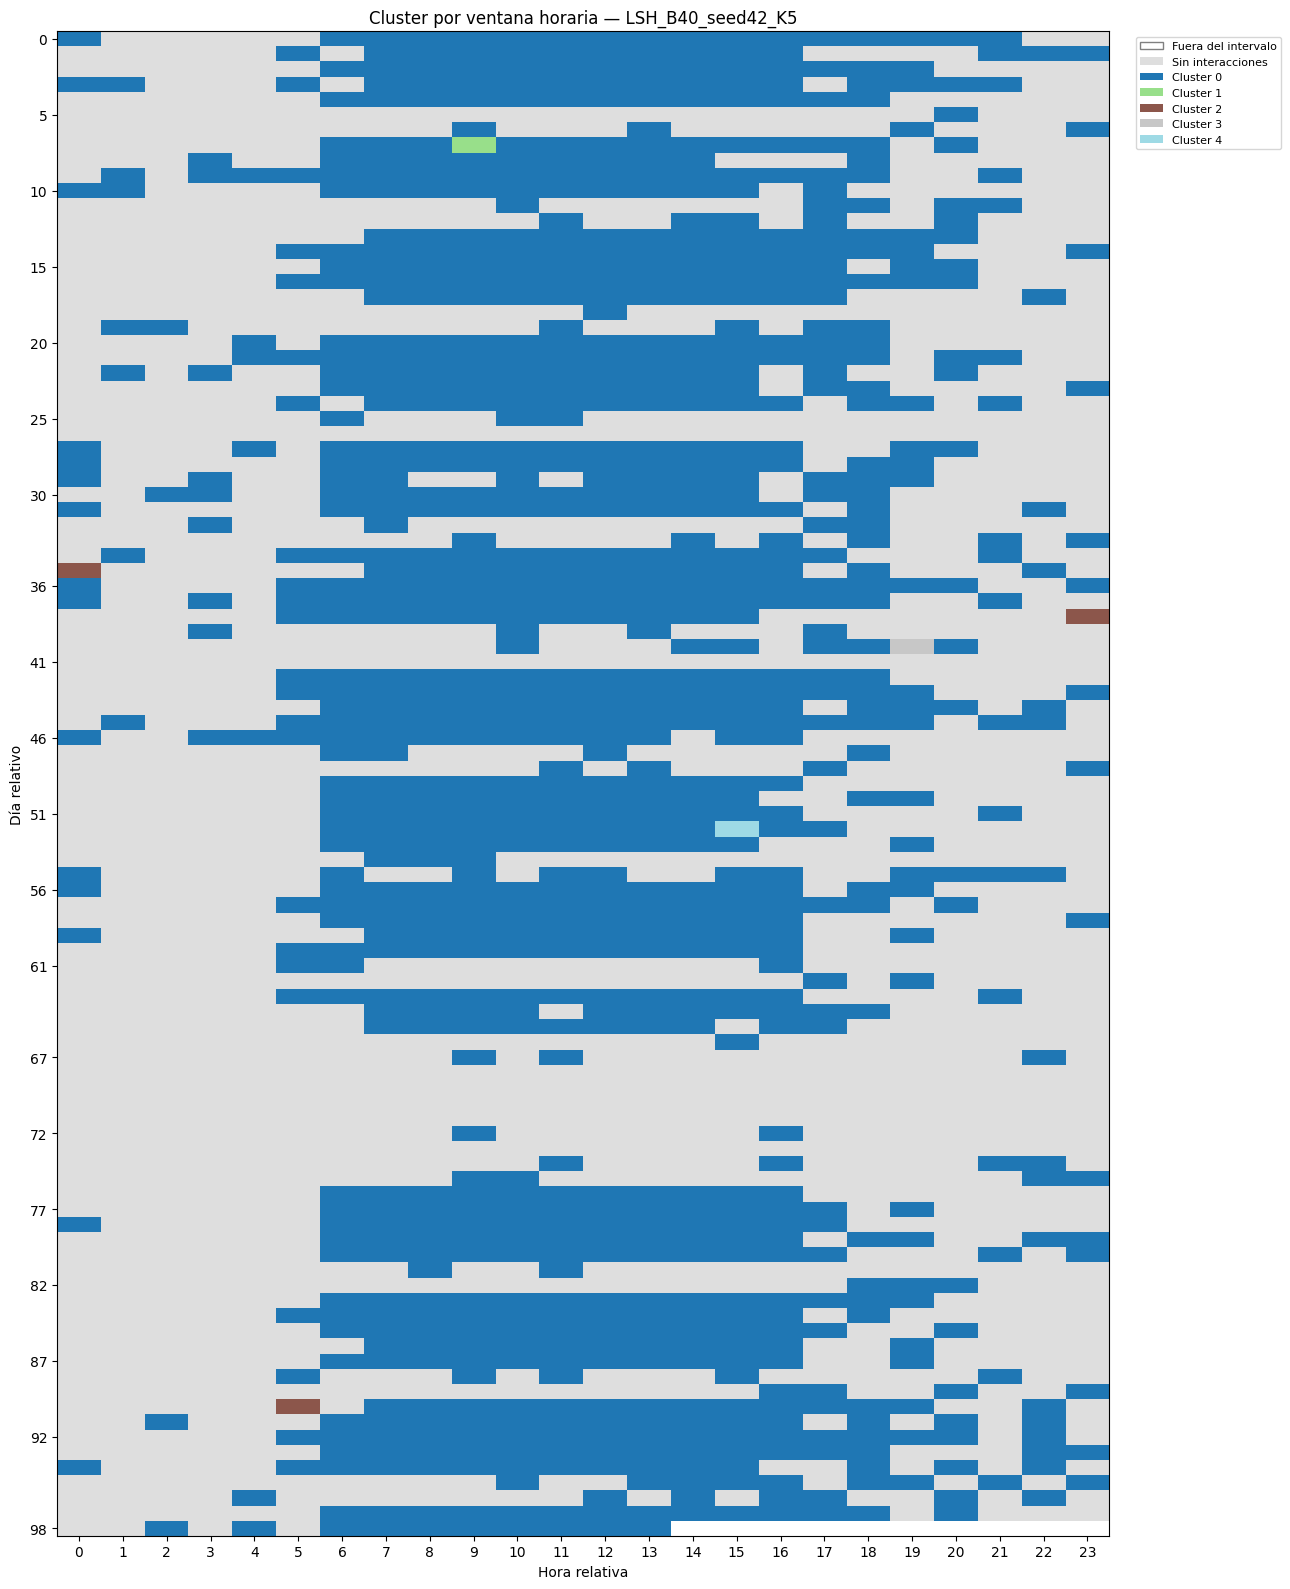

Perfil departamental omitido: Dept1 no permite distinguir departamentos.


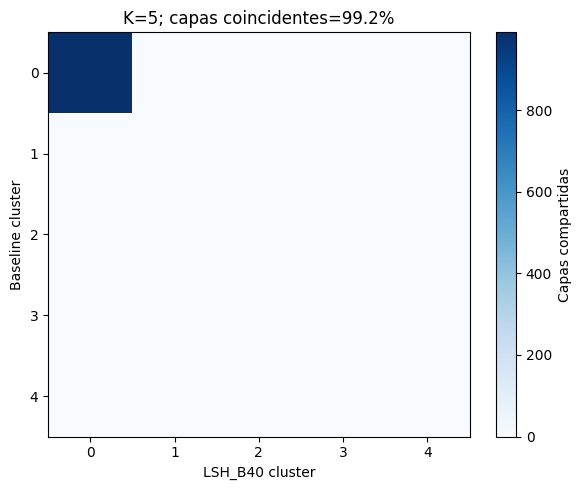


Actividad por cluster — baseline_seed42_K10
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           989          10.850354              8526.0           8.620829    7.494439      0.000157                  1.0                 8526.0                    0.0                              0.0
1             1           2.000000                 1.0           1.000000    1.000000      0.000021                  1.0                    1.0                    0.0                              0.0
2             1           2.000000                 1.0           1.000000    1.000000      0.000021                  1.0                    1.0            

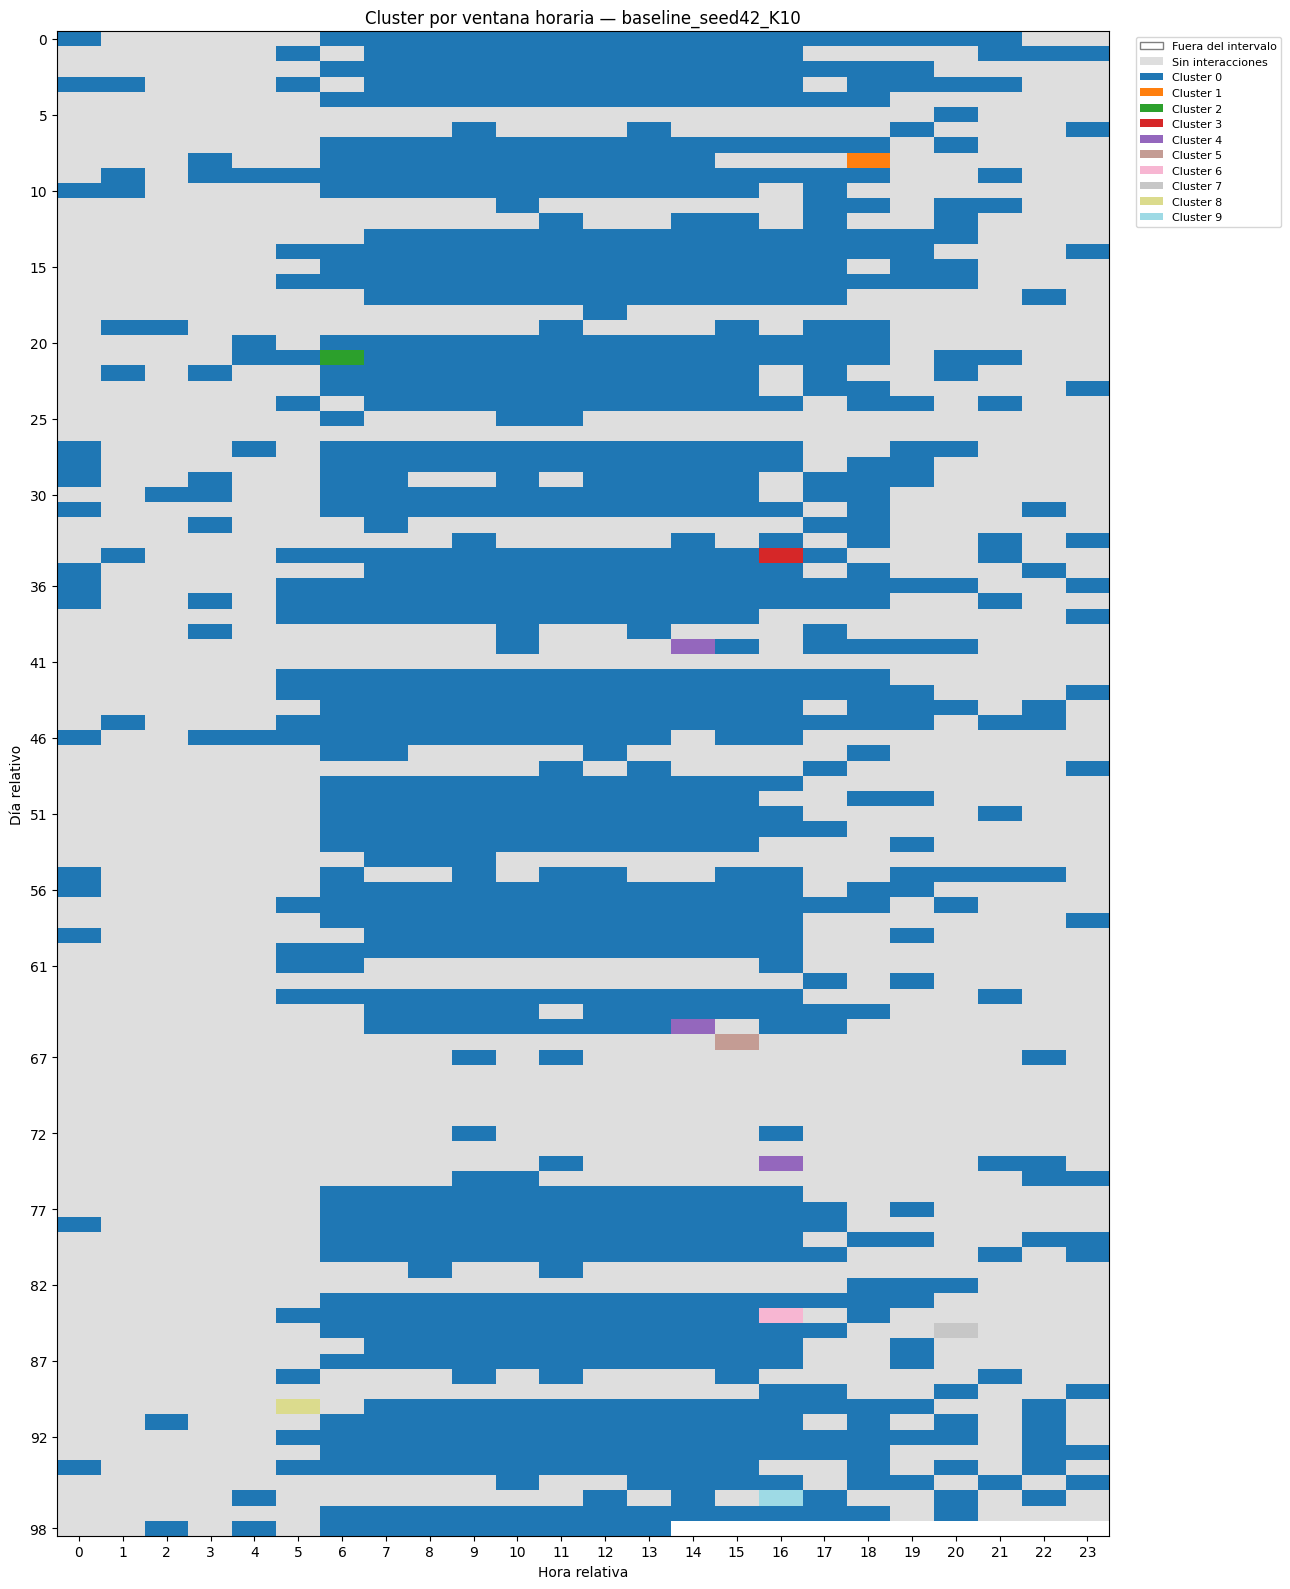

Perfil departamental omitido: Dept1 no permite distinguir departamentos.

Actividad por cluster — LSH_B10_seed42_K10
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           972           10.97428              8493.0           8.737654    7.592593      0.000160                  1.0                 8493.0                    0.0                              0.0
1             1            8.00000                 4.0           4.000000    4.000000      0.000084                  1.0                    4.0                    0.0                              0.0
2             8            2.50000                10.0           1.250000    1.2500

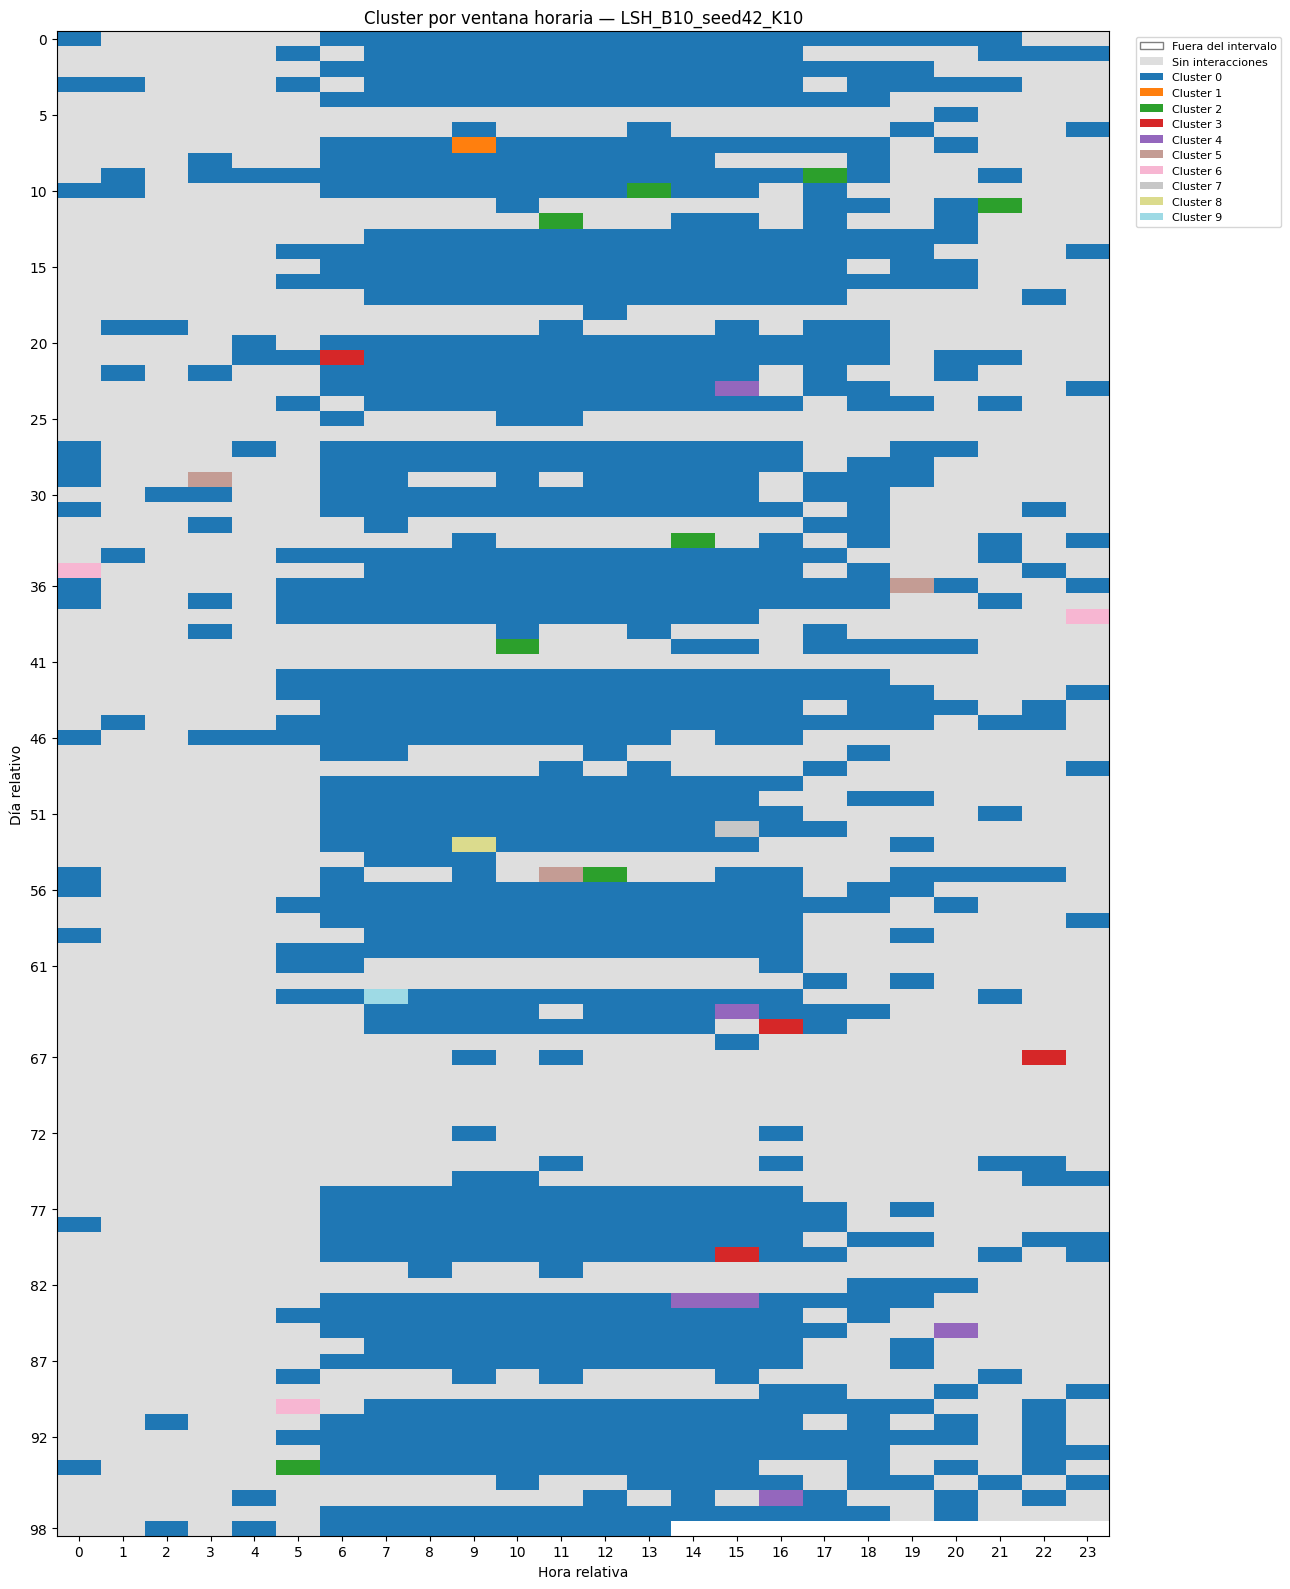

Perfil departamental omitido: Dept1 no permite distinguir departamentos.


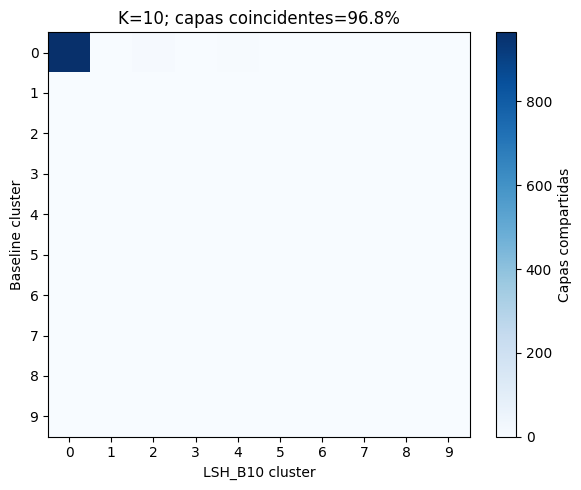


Actividad por cluster — LSH_B40_seed42_K10
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           977          10.931423              8499.0           8.699079    7.559877      0.000159                  1.0                 8499.0                    0.0                              0.0
1             1           8.000000                 4.0           4.000000    4.000000      0.000084                  1.0                    4.0                    0.0                              0.0
2             8           2.500000                10.0           1.250000    1.250000      0.000026                  1.0                   10.0             

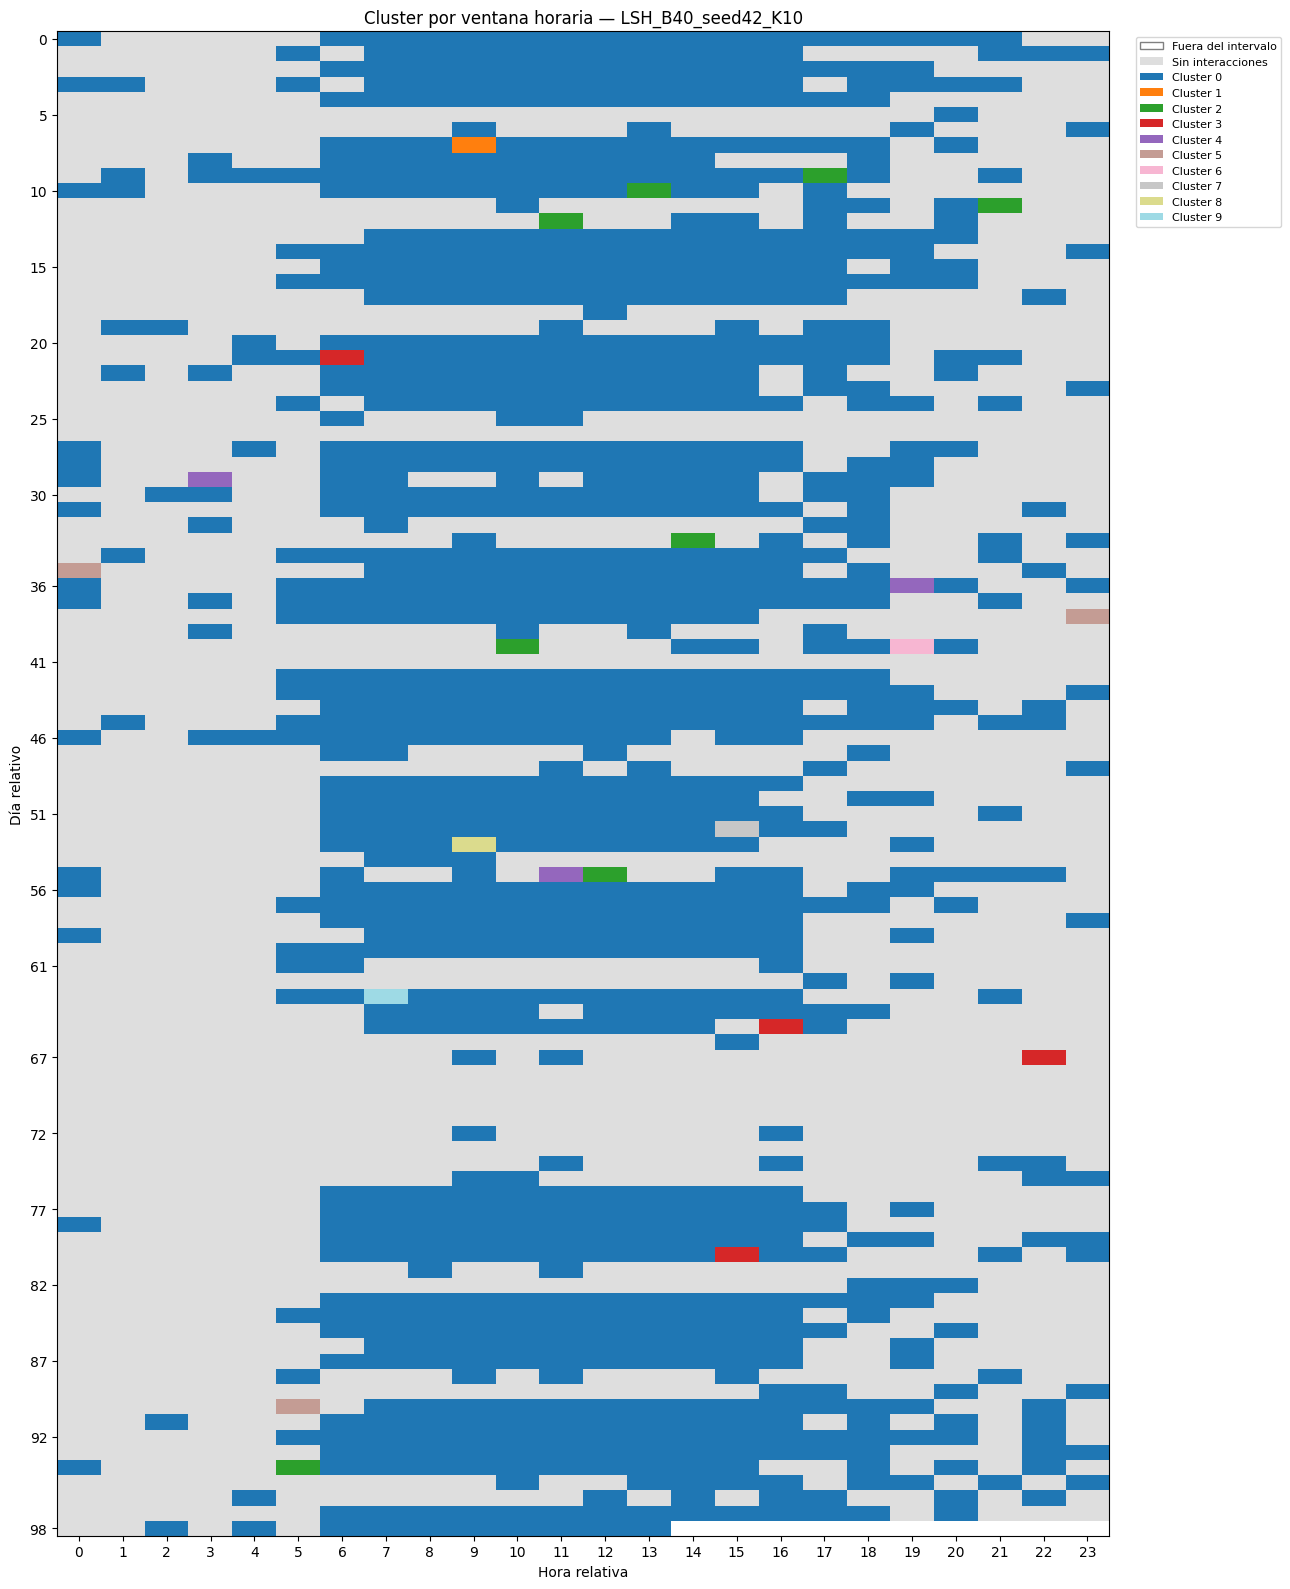

Perfil departamental omitido: Dept1 no permite distinguir departamentos.


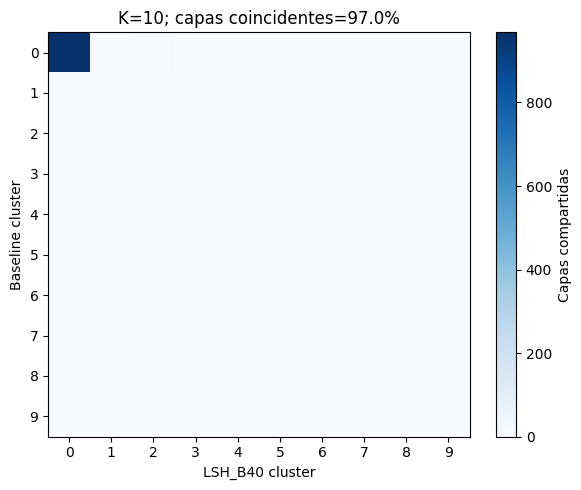


Actividad por cluster — baseline_seed42_K20
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           964          11.063278              8491.0           8.808091    7.653527      0.000161                  1.0                 8491.0                    0.0                              0.0
1             1           2.000000                 1.0           1.000000    1.000000      0.000021                  1.0                    1.0                    0.0                              0.0
2             7           2.571429                 9.0           1.285714    1.285714      0.000027                  1.0                    9.0            

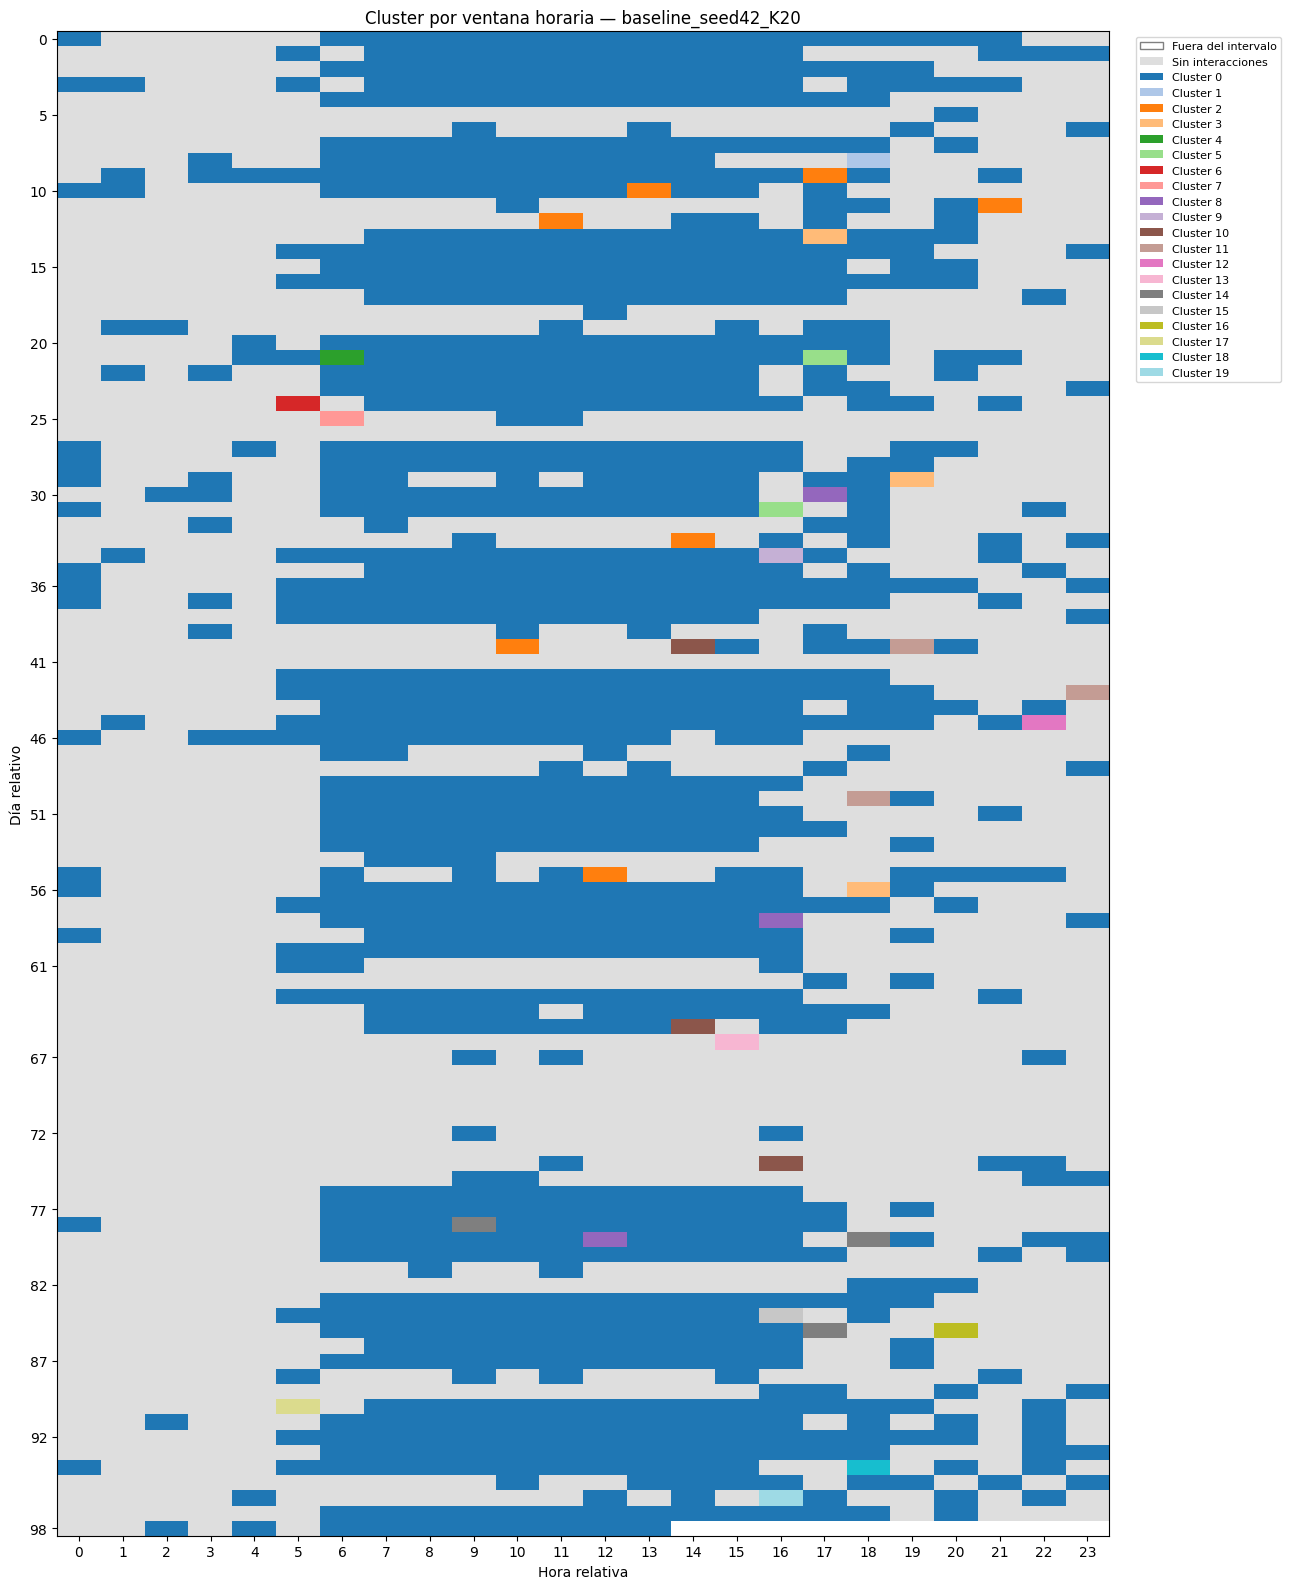

Perfil departamental omitido: Dept1 no permite distinguir departamentos.

Actividad por cluster — LSH_B10_seed42_K20
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           939          11.205538              8404.0           8.949947    7.777423      0.000163                  1.0                 8404.0                    0.0                              0.0
1             2           6.000000                 9.0           4.500000    3.500000      0.000074                  1.0                    9.0                    0.0                              0.0
2             1           8.000000                 4.0           4.000000    4.0000

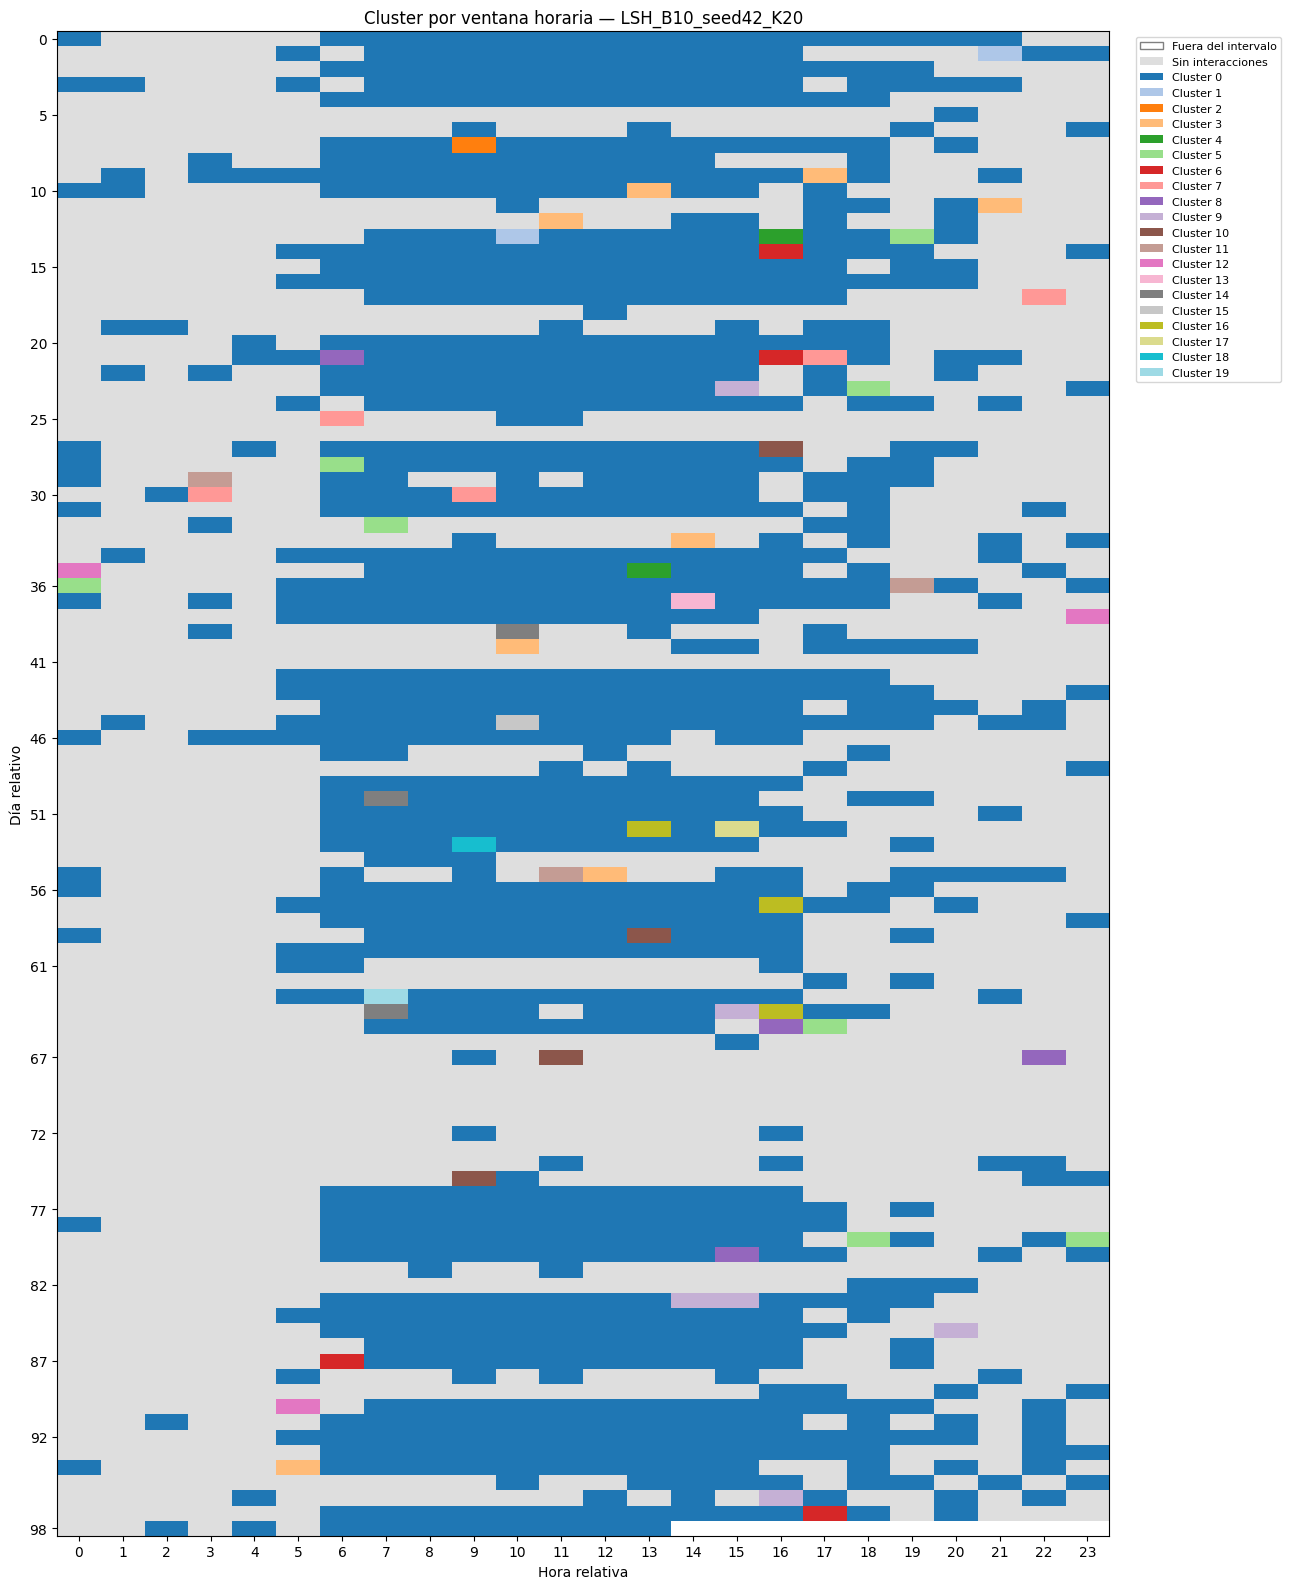

Perfil departamental omitido: Dept1 no permite distinguir departamentos.


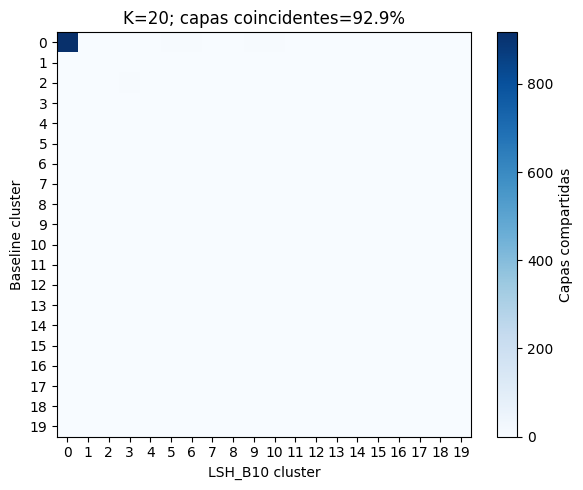


Actividad por cluster — LSH_B40_seed42_K20
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0           952          11.091387              8420.0           8.844538    7.689076      0.000162                  1.0                 8420.0                    0.0                              0.0
1             6           2.166667                 7.0           1.166667    1.166667      0.000025                  1.0                    7.0                    0.0                              0.0
2             1           8.000000                 4.0           4.000000    4.000000      0.000084                  1.0                    4.0             

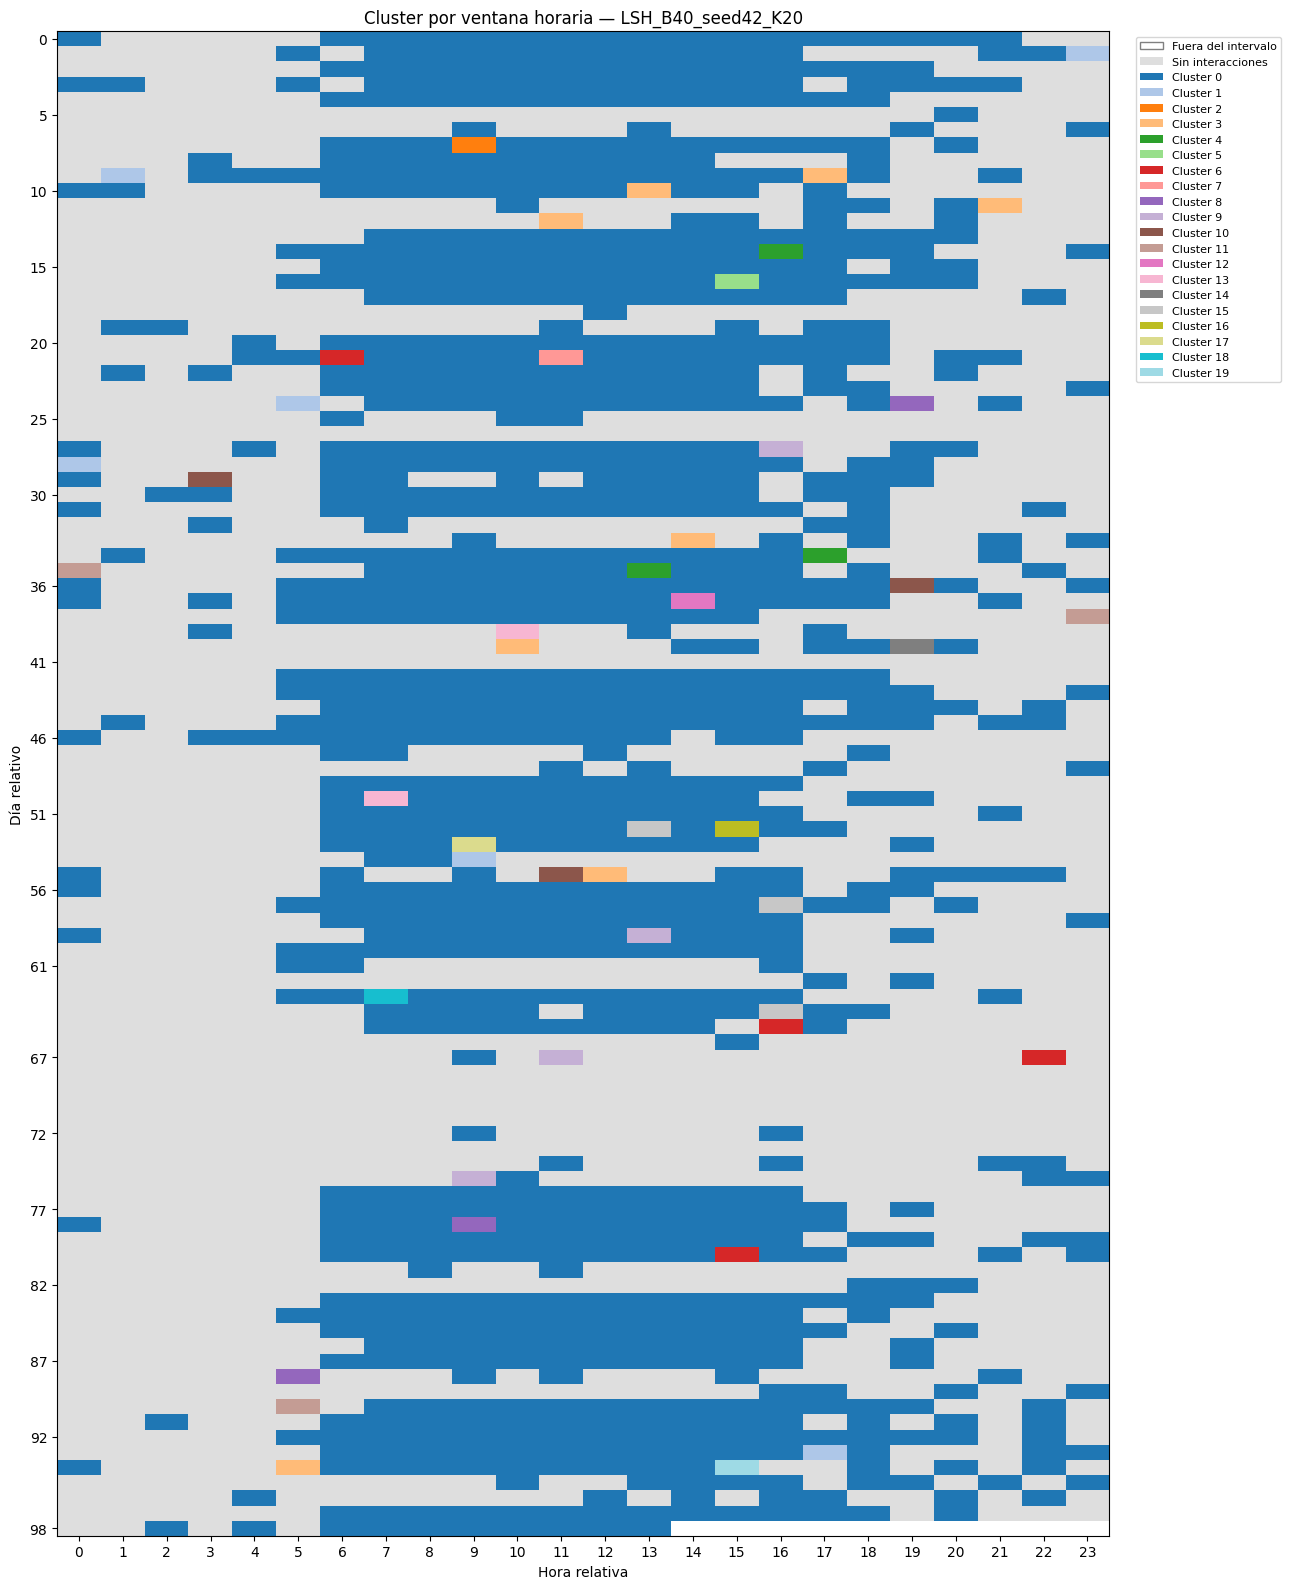

Perfil departamental omitido: Dept1 no permite distinguir departamentos.


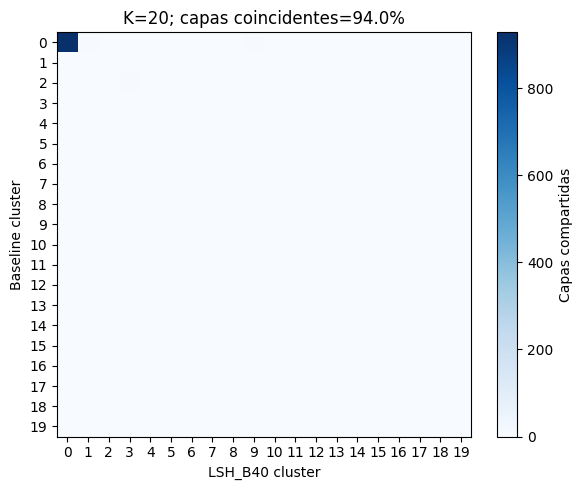

In [22]:
REPRESENTATIVE_SEED = FIRST_SEED
for k in FIXED_CLUSTER_COUNTS:
    base_labels = assignments[('baseline', FIRST_SEED, k)]
    for tag in ['baseline']+[f'LSH_B{B}' for B in EXPERIMENT_B_VALUES]:
        labels = assignments[(tag, REPRESENTATIVE_SEED, k)]
        name = f'{tag}_seed{REPRESENTATIVE_SEED}_K{k}'
        plot_temporal_analysis(graphs, labels, name, selection_metadata, experiment_dir/'interpretation')
        if tag != 'baseline':
            table, matched = overlap_table(base_labels, labels)
            table.to_csv(experiment_dir/f'{name}_overlap_baseline.csv')
            fig, ax = plt.subplots(figsize=(6,5))
            im = ax.imshow(table, cmap='Blues', aspect='auto')
            ax.set(xlabel=tag+' cluster', ylabel='Baseline cluster', title=f'K={k}; capas coincidentes={matched:.1%}')
            ax.set_xticks(range(len(table.columns)), table.columns)
            ax.set_yticks(range(len(table)), table.index)
            fig.colorbar(im, ax=ax, label='Capas compartidas')
            fig.tight_layout(); fig.savefig(experiment_dir/f'{name}_overlap.png', dpi=160)
            plt.show()
        recurrence = []
        for cluster in sorted(set(labels)):
            members = np.flatnonzero(labels==cluster)
            users, edges = defaultdict(int), defaultdict(int)
            for i in members:
                g = graphs[i]
                for u, degree in g.degree():
                    if degree: users[int(original_node_ids[u])] += 1
                for u,v in g.edges():
                    edges[tuple(sorted((int(original_node_ids[u]),int(original_node_ids[v]))))] += 1
            for kind, counts in [('user',users),('edge',edges)]:
                for item, count in sorted(counts.items(), key=lambda x:(-x[1],str(x[0])))[:10]:
                    recurrence.append(dict(cluster=int(cluster), kind=kind, item=str(item),
                        layers_present=count, cluster_layers=len(members), fraction=count/len(members)))
        pd.DataFrame(recurrence).to_csv(experiment_dir/f'{name}_recurrent_contacts.csv', index=False)


## Discusión y conclusiones: alcance de la evidencia
- **Dispersión:** documentar las densidades, usuarios activos y frecuencia de capas con una sola arista. La dispersión ofrece una hipótesis para la variabilidad entre proyecciones; demostrar causalidad requeriría otro experimento.
- **B como regularizador:** contrastar la dispersión de q, tamaños y membresías para B=10 y B=40. Si no hay mejora consistente, indicar que el comportamiento regularizador observado en Test 2 no se reproduce claramente aquí. Con K fijo, la varianza del número de clusters es cero por construcción y no sirve como evidencia de estabilidad.
- **Comparación justa:** todas las particiones se cortan al mismo K; q no elige ese K. Un q similar no garantiza membresías similares. El baseline es una referencia algorítmica, no una clasificación verdadera.
- **Sentido de los grupos:** contrastar los perfiles temporales, tamaños y contactos recurrentes con las matrices de solapamiento, y comprobar si el patrón persiste entre semillas antes de atribuir significado a una partición ilustrativa.
- **Trabajo futuro, sin cambiar este experimento:** estudiar una calidad q(C) ponderada por número de capas integrantes de cada cluster, especificando su normalización y validándola antes de usarla; explorar fusiones de buckets para reducir restricciones artificiales. Son oportunidades de mejora, no resultados demostrados ni cambios implementados aquí.

Los resultados calculados se exportan junto a las jerarquías. No se afirma que B=40 sea más estable, que los grupos sean comunidades ni que las propuestas futuras mejoren q hasta contar con evidencia.

In [23]:
4*4

16